# Chapter 4 Empirical Analysis

This notebook implements the **machine-learning and model-comparison components** of **Chapter 4**, aligned with the revised methodology described in **Chapter 3** (return construction, realised volatility proxy, rolling walk-forward forecasting, QLIKE evaluation, and multi-model comparison via SPA and MCS).

The **GARCH-family estimation and diagnostics** (GARCH, IGARCH, and GARCH-X) are produced in the companion **RMarkdown pipeline**, and the resulting parameter estimates and rolling forecasts are imported here for evaluation and hybrid modelling.

## Models covered in this notebook

1. **Random Forest (RF)** one-step-ahead volatility forecasts using lagged returns, volume, rolling volatility features, and sentiment lags
2. **RF + Sentiment** (explicit sentiment predictors included)
3. **Hybrid RF** augmented with **walk-forward GARCH/IGARCH conditional volatility forecasts** as an additional feature (**no look-ahead**, only information available at time (t))

> **Note:** GARCH/IGARCH and GARCH-X variance forecasts are treated as benchmark inputs generated from the R pipeline, ensuring consistent rolling estimation design across econometric and ML models.

## Forecasting design

* **One-step-ahead** forecasts
* **Rolling-window (walk-forward)** estimation and forecasting
* Rolling window length is configurable and applied consistently across models

## Evaluation

* Primary loss: **QLIKE** (Patton-style) evaluated against the realised volatility proxy (RV_t) used in Chapter 4
* Benchmark comparisons via **loss differentials**
* Multiple-model inference via **block bootstrap SPA** and **Model Confidence Set (MCS)**

## Reproducibility

This notebook is intended to run end-to-end. If you move data files, update `MERGED_FILE` (and any imported GARCH forecast file paths) in the configuration cell.


## 4.0: Load data and harmonize columns

Expected columns (minimum):
- `Date`
- `Close`
- `Volume`
- `Search_Interest` (or `Trends` which will be renamed)

The sample is then sorted, indexed by Date, and checked for missing values.


In [75]:
# ============================================
# IMPORT + ALIGN R GARCH-FAMILY OUTPUTS
# ============================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

# --------------------------------------------
# Paths
# --------------------------------------------
DATA_DIR = Path("../Data")
MERGED_FILE = DATA_DIR / "final_data.csv"

OUT_DIR = Path("./outputs")
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR = OUT_DIR / "figures"

GARCH_FAMILY_DIR = Path("./garch_family")
R_FORECAST_FILE = GARCH_FAMILY_DIR / "garch_family_oos_forecasts_from_r.csv"
R_PARAM_FILE = GARCH_FAMILY_DIR / "garch_family_params_from_r.csv"
R_DIAG_BASELINE_FILE = GARCH_FAMILY_DIR / "garch_family_baseline_diagnostics_from_r.csv"
R_DIAG_SENTIMENT_FILE = GARCH_FAMILY_DIR / "garch_family_sentiment_diagnostics_from_r.csv"
R_ARCHLM_FILE = GARCH_FAMILY_DIR / "garch_family_archlm_from_r.csv"

OUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------
# Helpers
# --------------------------------------------
def parse_date_column(s: pd.Series) -> pd.Series:
    """
    Robust date parsing to mirror the Rmd logic as closely as possible.
    """
    s1 = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    s2 = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    out = s1.fillna(s2)
    if out.isna().any():
        bad = s[out.isna()].head(10).tolist()
        raise ValueError(f"Date parsing failed for some rows. Examples: {bad}")
    return out


def assert_unique_monotonic_dates(df: pd.DataFrame, name: str) -> None:
    if "Date" not in df.columns:
        raise KeyError(f"{name} has no 'Date' column.")
    if df["Date"].duplicated().any():
        dups = df.loc[df["Date"].duplicated(), "Date"].astype(str).tolist()[:10]
        raise ValueError(f"{name} has duplicate Date values. Examples: {dups}")
    if not df["Date"].is_monotonic_increasing:
        raise ValueError(f"{name} Date is not sorted ascending.")


def save_table_latex(df, filename, caption=None, label=None, float_fmt="%.4f"):
    """
    Save a pandas DataFrame as a LaTeX table in TABLE_DIR.
    """
    output_path = TABLE_DIR / filename

    latex_str = df.to_latex(
        float_format=(lambda x: float_fmt % x),
        caption=caption,
        label=label
    )

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(latex_str)

    print(f"LaTeX table saved to: {output_path}")

def save_figure_png(filename, dpi=300, bbox_inches="tight"):
    """
    Save the current matplotlib figure to FIG_DIR as a PNG.
    """
    output_path = FIG_DIR / filename
    plt.savefig(output_path, dpi=dpi, bbox_inches=bbox_inches)
    print(f"Figure saved to: {output_path}")

def sanitize_dataframe_columns(df: pd.DataFrame) -> pd.DataFrame:
    """
    Clean DataFrame column names for presentation/export.
    """
    df = df.copy()
    df.columns = [str(col).strip() for col in df.columns]
    return df

# --------------------------------------------
# 1. Load raw thesis data
# --------------------------------------------
df = pd.read_csv(MERGED_FILE)
df["Date"] = parse_date_column(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Harmonise sentiment column name to match the Rmd
if "Trends" in df.columns and "Search_Interest" not in df.columns:
    df["Search_Interest"] = df["Trends"]

# Log returns in percent, matching R:
# r = 100 * (log(Close) - log(lag(Close)))
df["r"] = 100 * (np.log(df["Close"]) - np.log(df["Close"].shift(1)))

# Drop the first NA return row
df = df.loc[df["r"].notna()].copy()

# Create lagged sentiment, matching Rmd:
# Search_Interest_lag = lag(Search_Interest)
if "Search_Interest" not in df.columns:
    raise KeyError("Neither 'Search_Interest' nor 'Trends' found in final_data.csv.")

df["Search_Interest_lag"] = df["Search_Interest"].shift(1)

# Drop rows made invalid by lagging sentiment
# This is the effective sample used by GARCH-X / IGARCH-X in the Rmd
df_model = df.loc[df["Search_Interest_lag"].notna()].copy().reset_index(drop=True)

assert_unique_monotonic_dates(df_model, "df_model")

print("Effective modelling sample rebuilt in Python.")
print("Date range:", df_model["Date"].min().date(), "to", df_model["Date"].max().date())
print("Rows:", len(df_model))

# --------------------------------------------
# 2. Recreate the OOS split used in the Rmd
# --------------------------------------------
TEST_SIZE = 0.20
N = len(df_model)
split_idx = int(np.floor((1 - TEST_SIZE) * N))
n_oos = N - split_idx

oos_dates_python = df_model.loc[split_idx:, "Date"].reset_index(drop=True)
realized_var_python = (df_model.loc[split_idx:, "r"] ** 2).reset_index(drop=True)

oos_reference = pd.DataFrame({
    "Date": oos_dates_python,
    "Realized_Variance_Python": realized_var_python
})

assert_unique_monotonic_dates(oos_reference, "oos_reference")

print("\nPython OOS reference:")
print("Split index:", split_idx)
print("OOS rows:", len(oos_reference))
print("OOS range:", oos_reference["Date"].min().date(), "to", oos_reference["Date"].max().date())

# --------------------------------------------
# 3. Load R forecast file
# --------------------------------------------
r_fc = pd.read_csv(R_FORECAST_FILE)
r_fc["Date"] = parse_date_column(r_fc["Date"])
r_fc = r_fc.sort_values("Date").reset_index(drop=True)

assert_unique_monotonic_dates(r_fc, "r_fc")

expected_forecast_cols = [
    "Realized_Variance",
    "GARCH_Normal",
    "GARCH_Student_t",
    "GARCHX_Normal",
    "GARCHX_Student_t",
    "IGARCH_Normal",
    "IGARCH_Student_t",
    "IGARCHX_Normal",
    "IGARCHX_Student_t",
]
missing_cols = [c for c in expected_forecast_cols if c not in r_fc.columns]
if missing_cols:
    raise KeyError(f"R forecast file is missing columns: {missing_cols}")

print("\nR forecast file loaded.")
print("Rows:", len(r_fc))
print("Range:", r_fc["Date"].min().date(), "to", r_fc["Date"].max().date())

# --------------------------------------------
# 4. Strict alignment check: Python OOS vs R OOS
# --------------------------------------------
if len(r_fc) != len(oos_reference):
    print("\nWARNING: Row counts differ.")
    print("R forecast rows:", len(r_fc))
    print("Python OOS rows:", len(oos_reference))

# Compare normalized numpy arrays, not Series.equals()
dates_r = pd.to_datetime(r_fc["Date"]).dt.normalize().to_numpy()
dates_py = pd.to_datetime(oos_reference["Date"]).dt.normalize().to_numpy()

same_dates_in_order = (
    len(dates_r) == len(dates_py)
    and np.array_equal(dates_r, dates_py)
)

if same_dates_in_order:
    print("\nDate alignment check: PASSED (same dates in same order).")
else:
    print("\nDate alignment check: NOT identical in-order.")

    merged_dates = r_fc[["Date"]].merge(
        oos_reference[["Date"]],
        on="Date",
        how="outer",
        indicator=True
    )
    print(merged_dates["_merge"].value_counts(dropna=False))

    common_len = min(len(dates_r), len(dates_py))
    mismatch_idx = np.where(dates_r[:common_len] != dates_py[:common_len])[0]

    if len(mismatch_idx) > 0:
        print("\nFirst mismatches:")
        for j in mismatch_idx[:10]:
            print(
                f"Row {j}: R = {r_fc['Date'].iloc[j]} | Python = {oos_reference['Date'].iloc[j]}"
            )
    else:
        print("\nNo actual date mismatches found; likely dtype/precision issue only.")

print("R date dtype:", r_fc["Date"].dtype)
print("Python date dtype:", oos_reference["Date"].dtype)

# --------------------------------------------
# 5. Merge on Date only
# --------------------------------------------
eval_df = oos_reference.merge(
    r_fc,
    on="Date",
    how="inner",
    validate="one_to_one"
).sort_values("Date").reset_index(drop=True)

if len(eval_df) != len(oos_reference):
    raise ValueError(
        "Merged evaluation frame is shorter than Python OOS reference. "
        "Date alignment failed."
    )

# --------------------------------------------
# 6. Check realised variance consistency
# --------------------------------------------
eval_df["rv_diff"] = eval_df["Realized_Variance_Python"] - eval_df["Realized_Variance"]
max_abs_diff = eval_df["rv_diff"].abs().max()

print("\nRealized variance consistency:")
print("Max absolute difference:", max_abs_diff)

if max_abs_diff < 1e-10:
    print("Realized variance check: PASSED")
else:
    print("Realized variance check: NOT PASSED")
    print(
        eval_df.loc[
            eval_df["rv_diff"].abs() > 1e-10,
            ["Date", "Realized_Variance_Python", "Realized_Variance", "rv_diff"]
        ].head(10)
    )

# Master target
eval_df["Realized"] = eval_df["Realized_Variance_Python"]

# --------------------------------------------
# 7. Final forecast dictionary for evaluation
# --------------------------------------------
forecast_cols = [
    "GARCH_Normal",
    "GARCH_Student_t",
    "GARCHX_Normal",
    "GARCHX_Student_t",
    "IGARCH_Normal",
    "IGARCH_Student_t",
    "IGARCHX_Normal",
    "IGARCHX_Student_t",
]

forecast_dict = {col: eval_df[col].copy() for col in forecast_cols}

print("\nFinal evaluation frame ready.")
print("Shape:", eval_df.shape)
print("Date range:", eval_df["Date"].min().date(), "to", eval_df["Date"].max().date())
print("\nHead:")
print(eval_df[["Date", "Realized"] + forecast_cols].head())
print("\nTail:")
print(eval_df[["Date", "Realized"] + forecast_cols].tail())

# --------------------------------------------
# 8. Optional: load parameter and diagnostic files
# --------------------------------------------
garch_params_r = pd.read_csv(R_PARAM_FILE) if R_PARAM_FILE.exists() else pd.DataFrame()
garch_diag_baseline_r = pd.read_csv(R_DIAG_BASELINE_FILE) if R_DIAG_BASELINE_FILE.exists() else pd.DataFrame()
garch_diag_sentiment_r = pd.read_csv(R_DIAG_SENTIMENT_FILE) if R_DIAG_SENTIMENT_FILE.exists() else pd.DataFrame()
garch_archlm_r = pd.read_csv(R_ARCHLM_FILE) if R_ARCHLM_FILE.exists() else pd.DataFrame()

print("\nAuxiliary R outputs:")
print("Params rows:", len(garch_params_r))
print("Baseline diagnostics rows:", len(garch_diag_baseline_r))
print("Sentiment diagnostics rows:", len(garch_diag_sentiment_r))
print("ARCH-LM rows:", len(garch_archlm_r))

Effective modelling sample rebuilt in Python.
Date range: 2017-01-03 to 2025-08-09
Rows: 3141

Python OOS reference:
Split index: 2512
OOS rows: 629
OOS range: 2023-11-20 to 2025-08-09

R forecast file loaded.
Rows: 629
Range: 2023-11-20 to 2025-08-09

Date alignment check: PASSED (same dates in same order).
R date dtype: datetime64[us]
Python date dtype: datetime64[s]

Realized variance consistency:
Max absolute difference: 7.105427357601002e-15
Realized variance check: PASSED

Final evaluation frame ready.
Shape: (629, 13)
Date range: 2023-11-20 to 2025-08-09

Head:
        Date   Realized  GARCH_Normal  GARCH_Student_t  GARCHX_Normal  \
0 2023-11-20   0.058338      4.906703         9.431624       4.906696   
1 2023-11-21  20.604901      4.778366         8.663161       4.778103   
2 2023-11-22  19.537628      5.137439         9.848868       5.137432   
3 2023-11-23   0.145924      5.496478        11.363585       5.496538   
4 2023-11-24   1.318566      5.344907        10.304499      

### 4.1.0 Transformations

In [76]:
# =========================
# 2. Transformations
# =========================

def prepare_returns(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = df_in.copy()

    # ----------------------------------
    # Log returns (percentage)
    # r_t = 100 * (log P_t - log P_{t-1})
    # ----------------------------------
    df_out["log_return"] = np.log(df_out["Close"]).diff() * 100

    # ----------------------------------
    # Volatility components
    # ----------------------------------
    df_out["sq_return"] = df_out["log_return"] ** 2
    df_out["abs_return"] = df_out["log_return"].abs()

    # ----------------------------------
    # Realised volatility proxy
    # RV_t = r_t^2
    # ----------------------------------
    df_out["RV"] = df_out["sq_return"]

    # ----------------------------------
    # Log trading volume
    # ----------------------------------
    df_out["log_volume"] = np.log(df_out["Volume"].replace(0, np.nan))

    # ----------------------------------
    # Lagged sentiment
    # ----------------------------------
    df_out["Search_Interest_lag"] = df_out["Search_Interest"].shift(1)

    # ----------------------------------
    # Drop rows made invalid by lags/logging
    # ----------------------------------
    df_out = df_out.dropna(
        subset=[
            "log_return",
            "sq_return",
            "abs_return",
            "RV",
            "log_volume",
            "Search_Interest_lag",
        ]
    ).copy()

    # ----------------------------------
    # Safety check
    # ----------------------------------
    if np.isinf(df_out.select_dtypes(include=[np.number])).any().any():
        raise ValueError("Infinite values detected after transformations.")

    print(f"Transformations complete. Sample size: {len(df_out)}")
    print(f"Sample: {df_out.index.min().date()} → {df_out.index.max().date()}")

    return df_out


# ----------------------------------
# Reload raw data cleanly for Python-side transformations
# ----------------------------------
df_raw = pd.read_csv(MERGED_FILE)
df_raw["Date"] = parse_date_column(df_raw["Date"])
df_raw = df_raw.sort_values("Date").reset_index(drop=True)

# Harmonise sentiment column name
if "Trends" in df_raw.columns and "Search_Interest" not in df_raw.columns:
    df_raw["Search_Interest"] = df_raw["Trends"]

required_cols = ["Date", "Close", "Volume", "Search_Interest"]
missing_cols = [c for c in required_cols if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Missing required columns for transformations: {missing_cols}")

# Ensure numeric inputs
for col in ["Close", "Volume", "Search_Interest"]:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

df_raw = df_raw.dropna(subset=["Close", "Volume", "Search_Interest"]).copy()

# Set Date index for time-series operations
df_raw = df_raw.set_index("Date").sort_index()

if df_raw.index.duplicated().any():
    dupes = df_raw.index[df_raw.index.duplicated()].unique()[:10]
    raise ValueError(f"Duplicate dates detected in df_raw. Examples: {list(dupes)}")

# ----------------------------------
# Execute transformations
# ----------------------------------
df_transformed = prepare_returns(df_raw)

print("\nPreview:")
display(df_transformed.head())

print("\nColumns:")
print(df_transformed.columns.tolist())

Transformations complete. Sample size: 3142
Sample: 2017-01-02 → 2025-08-09

Preview:


,Open,Close,Volume,Trends,Search_Interest,log_return,sq_return,abs_return,RV,log_volume,Search_Interest_lag
Date,,,,,,,,,,,
2017-01-02,998.617004,1021.750000,222184992.0,27,27,2.319324,5.379262,2.319324,5.379262,19.219021,14.0
2017-01-03,1021.599976,1043.839966,185168000.0,25,25,2.138934,4.575041,2.138934,4.575041,19.036774,27.0
2017-01-04,1044.400024,1154.729980,344945984.0,28,28,10.096034,101.929912,10.096034,101.929912,19.658898,25.0
2017-01-05,1156.729980,1013.380005,510199008.0,35,35,-13.057525,170.498959,13.057525,170.498959,20.050311,28.0
2017-01-06,1014.239990,902.200989,351876000.0,29,29,-11.620924,135.045878,11.620924,135.045878,19.678789,35.0



Columns:
['Open', 'Close', 'Volume', 'Trends', 'Search_Interest', 'log_return', 'sq_return', 'abs_return', 'RV', 'log_volume', 'Search_Interest_lag']


### 4.1.1: Core distributional statistics
We calculate the mean, standard deviation, minimum and maximum values, skewness, and Kurtosis

In [77]:
# -------------------------
# 4.1.1 Core Descriptive Statistics
# -------------------------

def core_descriptive_stats(series: pd.Series) -> pd.Series:
    """
    Compute key descriptive statistics for a given series.
    """
    s = series.dropna()

    return pd.Series({
        "Mean": s.mean(),
        "Median": s.median(),
        "Std. Dev.": s.std(),
        "Min": s.min(),
        "Max": s.max(),
        "Skewness": s.skew(),
        "Excess Kurtosis": s.kurt()
    })


# Construct table
desc_411 = pd.concat({
    "Returns": core_descriptive_stats(df_transformed["log_return"]),
    "Realised Volatility (Squared Returns)": core_descriptive_stats(df_transformed["RV"]),
    "Lagged Sentiment": core_descriptive_stats(df_transformed["Search_Interest_lag"])
}, axis=1)

# Save to LaTeX
save_table_latex(
    desc_411,
    "core_descriptives.tex",
    caption="Core descriptive statistics for returns, realised volatility proxied by squared returns, and lagged sentiment.",
    label="tab:descriptive_stats",
    float_fmt="%.4f"
)

# Display in notebook
print("Core descriptive statistics:")
display(desc_411)

LaTeX table saved to: outputs/tables/core_descriptives.tex
Core descriptive statistics:


,Returns,Realised Volatility (Squared Returns),Lagged Sentiment
Mean,0.151482,13.599002,37.558561
Median,0.127514,2.359679,36.000000
Std. Dev.,3.685156,49.966437,18.419159
Min,-46.473018,0.000000,5.000000
Max,22.511895,2159.741359,100.000000
Skewness,-0.659734,26.923011,0.658906
Excess Kurtosis,11.663784,1093.438075,0.320546


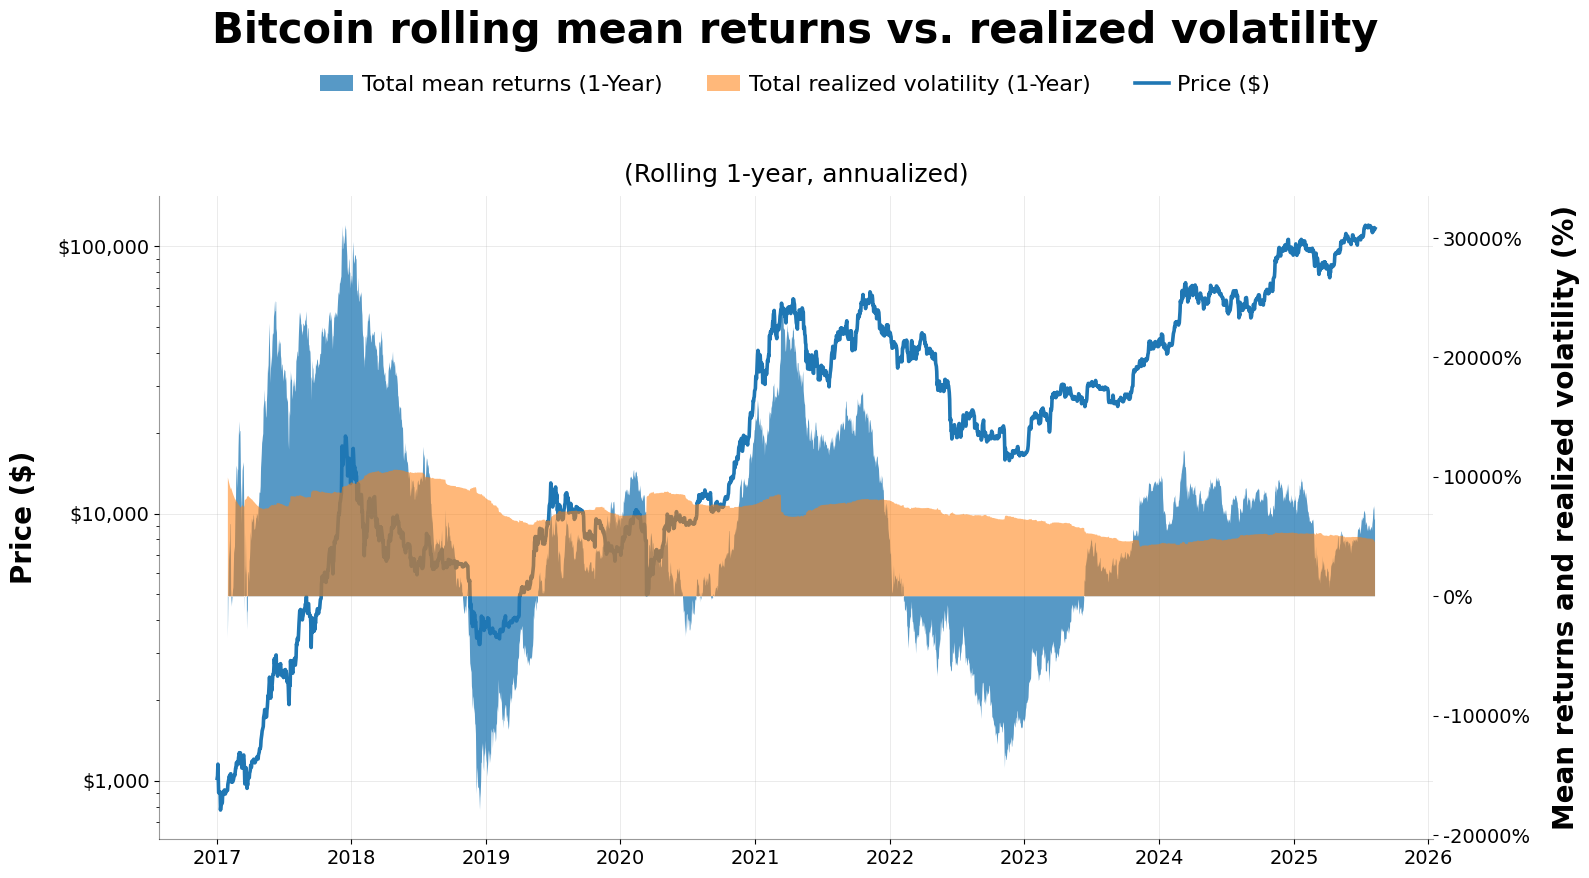

Saved: outputs/figures/bitcoin_returns_vs_realized_volatility.png


In [78]:
# ============================================================
# Descriptive market summary figure
#   • Bitcoin price (log scale)
#   • Rolling annualized mean returns
#   • Rolling annualized realized volatility
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

PRICE_COL = "Close"          # change if needed
RETURN_COL = "log_return"    # already in your workflow
RV_COL = "sq_return"         # squared returns
ROLLING_DAYS = 365
TRADING_DAYS = 365           # for crypto, 365 is fine

# ------------------------------------------------------------
# Use transformed dataset
# ------------------------------------------------------------
df_plot = df_transformed.copy().sort_index()

required_cols = [PRICE_COL, RETURN_COL, RV_COL]
missing = [c for c in required_cols if c not in df_plot.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

# ------------------------------------------------------------
# Rolling annualized measures
# ------------------------------------------------------------
# Mean return annualized (approx.)
df_plot["roll_mean_return_ann"] = (
    df_plot[RETURN_COL]
    .rolling(ROLLING_DAYS, min_periods=30)
    .mean() * TRADING_DAYS * 100
)

# Realized volatility annualized from squared returns
df_plot["roll_realized_vol_ann"] = (
    np.sqrt(
        df_plot[RV_COL]
        .rolling(ROLLING_DAYS, min_periods=30)
        .mean() * TRADING_DAYS
    ) * 100
)

# ------------------------------------------------------------
# Plot style
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (16, 9),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 28,
    "axes.labelsize": 20,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 16,
    "font.weight": "regular",
})

fig, ax_price = plt.subplots(figsize=(16, 9))
ax_stats = ax_price.twinx()

# ------------------------------------------------------------
# Filled area: rolling mean returns
# ------------------------------------------------------------
ax_stats.fill_between(
    df_plot.index,
    0,
    df_plot["roll_mean_return_ann"],
    alpha=0.75,
    label="Total mean returns (1-Year)",
)

# ------------------------------------------------------------
# Filled area: rolling realized volatility
# ------------------------------------------------------------
ax_stats.fill_between(
    df_plot.index,
    0,
    df_plot["roll_realized_vol_ann"],
    alpha=0.55,
    label="Total realized volatility (1-Year)",
)

# ------------------------------------------------------------
# Price line
# ------------------------------------------------------------
ax_price.plot(
    df_plot.index,
    df_plot[PRICE_COL],
    linewidth=2.6,
    label="Price ($)",
)

# ------------------------------------------------------------
# Axes formatting
# ------------------------------------------------------------
ax_price.set_yscale("log")
ax_price.set_ylabel("Price ($)", fontweight="bold", labelpad=14)
ax_stats.set_ylabel("Mean returns and realized volatility (%)", fontweight="bold", labelpad=16)

ax_price.xaxis.set_major_locator(mdates.YearLocator())
ax_price.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def dollar_fmt(x, pos):
    if x >= 1:
        return f"${x:,.0f}"
    return f"${x:.0f}"

def percent_fmt(x, pos):
    return f"{x:.0f}%"

ax_price.yaxis.set_major_formatter(FuncFormatter(dollar_fmt))
ax_stats.yaxis.set_major_formatter(FuncFormatter(percent_fmt))

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------
fig.suptitle(
    "Bitcoin rolling mean returns vs. realized volatility",
    fontsize=30,
    fontweight="bold",
    y=0.97
)
ax_price.set_title("(Rolling 1-year, annualized)", fontsize=18, pad=10)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------
handles_price, labels_price = ax_price.get_legend_handles_labels()
handles_stats, labels_stats = ax_stats.get_legend_handles_labels()

fig.legend(
    handles_stats + handles_price,
    labels_stats + labels_price,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.92),
    handlelength=1.5,
    handletextpad=0.4
)

# ------------------------------------------------------------
# Cosmetic cleanup
# ------------------------------------------------------------
ax_price.grid(True, which="major", axis="both", alpha=0.25)
ax_stats.grid(False)

ax_price.spines["left"].set_alpha(0.4)
ax_price.spines["bottom"].set_alpha(0.4)
ax_stats.spines["top"].set_visible(False)
ax_stats.spines["left"].set_visible(False)
ax_stats.spines["bottom"].set_visible(False)

fig.tight_layout(rect=[0, 0, 1, 0.88])

out_file = FIG_DIR / "bitcoin_returns_vs_realized_volatility.png"
fig.savefig(out_file, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", out_file)

### 4.1.2 Quantiles and tail behaviour

In [79]:
# -------------------------
# 4.1.2 Quantiles and Tail Behaviour
# -------------------------

quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

quantile_412 = pd.DataFrame({
    "Returns": df_transformed["log_return"].dropna().quantile(quantiles),
    "Realised Volatility (Squared Returns)": df_transformed["RV"].dropna().quantile(quantiles),
    "Lagged Sentiment": df_transformed["Search_Interest_lag"].dropna().quantile(quantiles)
})

# Clean percentage labels
quantile_412.index = [f"{int(q*100)}%" for q in quantiles]

# Save to LaTeX
save_table_latex(
    quantile_412,
    "quantiles_tail_behaviour.tex",
    caption="Quantiles illustrating tail behaviour of returns, realised volatility proxied by squared returns, and lagged sentiment.",
    label="tab:quantiles_tail_behaviour",
    float_fmt="%.4f"
)

print("Quantiles and tail behaviour:")
display(quantile_412)

LaTeX table saved to: outputs/tables/quantiles_tail_behaviour.tex
Quantiles and tail behaviour:


,Returns,Realised Volatility (Squared Returns),Lagged Sentiment
1%,-10.602982,0.000669,7.41
5%,-5.873204,0.012844,12.00
25%,-1.357782,0.387232,22.00
50%,0.127514,2.359679,36.00
75%,1.733894,10.719347,49.00
95%,5.844212,59.499894,70.00
99%,10.155747,146.332575,93.00


### 4.1.3 Dependence and persistence diagnostics

Figure saved to: outputs/figures/acf_returns.png


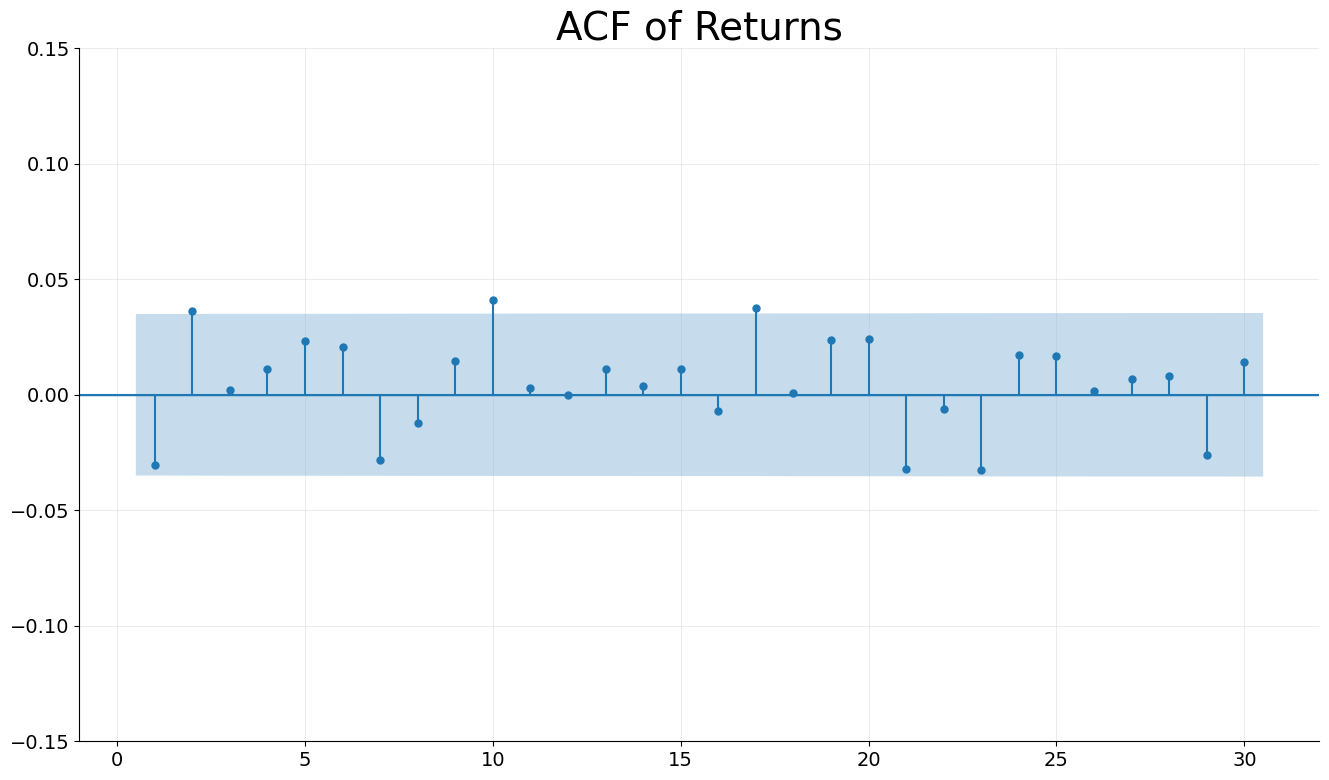

Figure saved to: outputs/figures/acf_realised_volatility.png


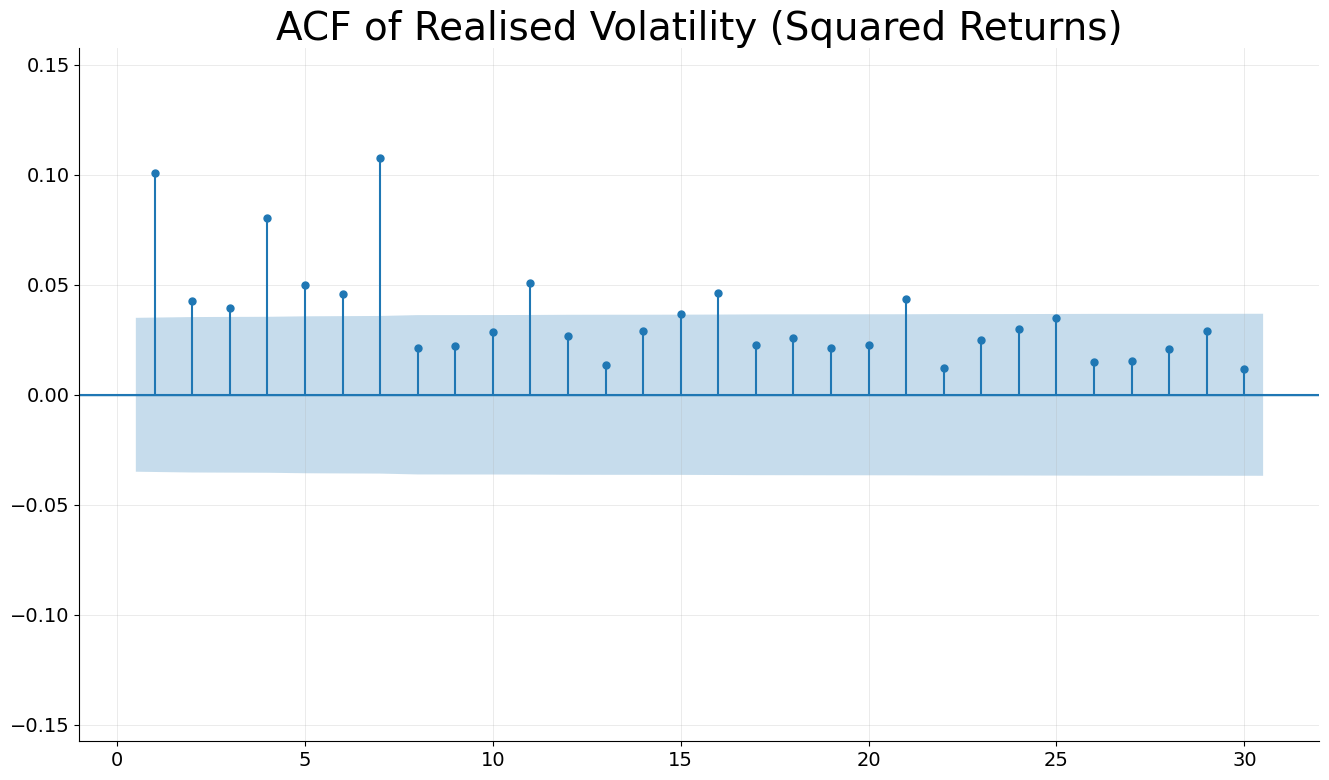

LaTeX table saved to: outputs/tables/ljung_box_dependence.tex
Ljung-Box dependence diagnostics:


,Returns,Realised Volatility (Squared Returns)
Lag 10,0.034366,7.190884e-21
Lag 20,0.094799,4.640968e-22
Lag 30,0.098065,8.330886e-22


In [80]:
# -------------------------
# 4.1.3 Dependence and Persistence Diagnostics
# -------------------------

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt
import numpy as np

ACF_LAGS = 30
MARGIN = 0.05  # extra padding


def dynamic_acf_plot(series, filename, title):
    series = series.dropna()

    acf_vals = acf(series, nlags=ACF_LAGS, fft=True)
    max_acf = np.max(np.abs(acf_vals[1:])) if len(acf_vals) > 1 else 0
    bound = max(max_acf + MARGIN, 0.15)

    fig, ax = plt.subplots()
    plot_acf(series, lags=ACF_LAGS, zero=False, ax=ax)

    ax.set_ylim(-bound, bound)
    ax.axhline(0, linewidth=1)
    ax.set_title(title)

    save_figure_png(filename)
    plt.show()
    plt.close(fig)


# -------------------------
# ACF of Returns
# -------------------------
dynamic_acf_plot(
    df_transformed["log_return"],
    "acf_returns.png",
    "ACF of Returns"
)

# -------------------------
# ACF of Realised Volatility
# -------------------------
dynamic_acf_plot(
    df_transformed["RV"],
    "acf_realised_volatility.png",
    "ACF of Realised Volatility (Squared Returns)"
)

# -------------------------
# Ljung-Box Tests
# -------------------------
lb_returns = acorr_ljungbox(
    df_transformed["log_return"].dropna(),
    lags=[10, 20, 30],
    return_df=True
)

lb_rv = acorr_ljungbox(
    df_transformed["RV"].dropna(),
    lags=[10, 20, 30],
    return_df=True
)

lb_table = pd.concat({
    "Returns": lb_returns["lb_pvalue"],
    "Realised Volatility (Squared Returns)": lb_rv["lb_pvalue"]
}, axis=1)

# Make lag labels cleaner
lb_table.index = [f"Lag {i}" for i in lb_table.index]

save_table_latex(
    lb_table,
    "ljung_box_dependence.tex",
    caption="Ljung–Box test p-values for dependence diagnostics of returns and realised volatility proxied by squared returns.",
    label="tab:ljung_box_dependence"
)

print("Ljung-Box dependence diagnostics:")
display(lb_table)

### 4.1.4 Normality and distributional tests
Jarque-Bera test
- statistic
- p-value

In [81]:
# -------------------------
# 4.1.4 Normality and Distributional Tests
# -------------------------

from scipy.stats import jarque_bera

def jarque_bera_test(series: pd.Series) -> pd.Series:
    s = series.dropna()
    jb_stat, jb_pvalue = jarque_bera(s)

    return pd.Series({
        "Observations": len(s),
        "JB Statistic": jb_stat,
        "p-value (JB)": jb_pvalue
    })


jb_414 = pd.concat({
    "Returns": jarque_bera_test(df_transformed["log_return"]),
    "Realised Volatility (Squared Returns)": jarque_bera_test(df_transformed["RV"])
}, axis=1)


save_table_latex(
    jb_414,
    "jarque_bera_tests.tex",
    caption="Jarque–Bera normality test results for returns and realised volatility proxied by squared returns.",
    label="tab:jarque_bera",
    float_fmt="%.4f"
)

print("Jarque-Bera normality tests:")
display(jb_414)

LaTeX table saved to: outputs/tables/jarque_bera_tests.tex
Jarque-Bera normality tests:


,Returns,Realised Volatility (Squared Returns)
Observations,3142.000000,3.142000e+03
JB Statistic,17975.682564,1.564060e+08
p-value (JB),0.000000,0.000000e+00


The Jarque–Bera test strongly rejects the null hypothesis of normality for returns, squared returns, and realised volatility (p < 0.001). The large test statistics reflect substantial skewness and excess kurtosis in the Bitcoin return distribution, consistent with heavy-tailed behaviour commonly observed in cryptocurrency markets. These findings motivate the inclusion of Student-t innovations in the GARCH framework and support the exploration of nonlinear machine learning approaches.

### 4.1.5: Stationarity diagnostics
ADF tests
KPSS tests for robustness

In [82]:
# -------------------------
# 4.1.5 ADF Stationarity Tests
# -------------------------

from statsmodels.tsa.stattools import adfuller

def adf_test(series: pd.Series, maxlag: int = None) -> pd.Series:
    s = series.dropna()

    result = adfuller(
        s,
        maxlag=maxlag,
        autolag="AIC",
        regression="c"  # constant included
    )

    return pd.Series({
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Used Lags": result[2],
        "Observations": result[3],
        "Critical Value (5%)": result[4]["5%"]
    })


adf_415 = pd.concat({
    "Returns": adf_test(df_transformed["log_return"]),
    "Realised Volatility (Squared Returns)": adf_test(df_transformed["RV"]),
    "Lagged Sentiment": adf_test(df_transformed["Search_Interest_lag"])
}, axis=1)


save_table_latex(
    adf_415,
    "adf_stationarity_tests.tex",
    caption="ADF unit root test results for returns, realised volatility proxied by squared returns, and lagged sentiment.",
    label="tab:adf",
    float_fmt="%.4f"
)

print("ADF stationarity tests:")
display(adf_415)

LaTeX table saved to: outputs/tables/adf_stationarity_tests.tex
ADF stationarity tests:


,Returns,Realised Volatility (Squared Returns),Lagged Sentiment
ADF Statistic,-38.812076,-1.674082e+01,-4.650133
p-value,0.000000,1.358719e-29,0.000104
Used Lags,1.000000,6.000000e+00,29.000000
Observations,3140.000000,3.135000e+03,3112.000000
Critical Value (5%),-2.862461,-2.862462e+00,-2.862469


The Augmented Dickey–Fuller tests reject the null hypothesis of a unit root for returns, squared returns, realised volatility, and sentiment (p < 0.01 in all cases). These findings indicate that all variables are stationary in levels, supporting the validity of ARCH/GARCH modelling and direct inclusion of sentiment measures without further differencing.

### 4.1.6 KPSS Stationarity Test

In [83]:
# -------------------------
# 4.1.6 KPSS Stationarity Tests
# -------------------------

from statsmodels.tsa.stattools import kpss

def kpss_test(series: pd.Series, regression: str = "c") -> pd.Series:
    s = series.dropna()

    stat, p_value, lags, _ = kpss(
        s,
        regression=regression,
        nlags="auto"
    )

    return pd.Series({
        "Observations": len(s),
        "KPSS Statistic": stat,
        "p-value": p_value,
        "Used Lags": lags
    })


kpss_416 = pd.concat({
    "Returns": kpss_test(df_transformed["log_return"]),
    "Realised Volatility (Squared Returns)": kpss_test(df_transformed["RV"]),
    "Lagged Sentiment": kpss_test(df_transformed["Search_Interest_lag"])
}, axis=1)

save_table_latex(
    kpss_416,
    "kpss_stationarity_tests.tex",
    caption="KPSS stationarity test results for returns, realised volatility proxied by squared returns, and lagged sentiment.",
    label="tab:kpss",
    float_fmt="%.4f"
)

print("KPSS stationarity tests:")
display(kpss_416)

LaTeX table saved to: outputs/tables/kpss_stationarity_tests.tex
KPSS stationarity tests:


,Returns,Realised Volatility (Squared Returns),Lagged Sentiment
Observations,3142.000000,3142.000000,3142.000000
KPSS Statistic,0.142971,2.151845,1.283793
p-value,0.100000,0.010000,0.010000
Used Lags,8.000000,17.000000,31.000000


While the ADF tests reject the presence of a unit root in all variables, the KPSS test rejects stationarity for squared returns, realised volatility, and sentiment. This apparent discrepancy reflects the high persistence typical of volatility and attention measures rather than genuine non-stationarity. In line with standard financial time-series evidence, the variables are treated as stationary but highly persistent processes suitable for ARCH/GARCH and machine learning modelling.

### 4.1.7 Correlation analysis
#### a: Correlation matrix

In [84]:
# -------------------------
# 4.1.7 Correlation Analysis
# -------------------------

corr_vars = [
    "log_return",
    "abs_return",
    "RV",
    "Search_Interest_lag"
]

# Rename for cleaner LaTeX output
corr_df = df_transformed[corr_vars].copy()
corr_df.columns = [
    "Returns",
    "Absolute Returns",
    "Realised Volatility (Squared Returns)",
    "Lagged Sentiment"
]

# -------------------------
# Pearson Correlation
# -------------------------
corr_417 = corr_df.corr().round(4)

save_table_latex(
    corr_417,
    "correlation_matrix.tex",
    caption="Pearson correlation matrix for returns, absolute returns, realised volatility proxied by squared returns, and lagged sentiment.",
    label="tab:correlation",
    float_fmt="%.4f"
)

print("Pearson correlation matrix:")
display(corr_417)

# -------------------------
# Spearman Correlation
# -------------------------
corr_417_spearman = corr_df.corr(method="spearman").round(4)

save_table_latex(
    corr_417_spearman,
    "correlation_matrix_spearman.tex",
    caption="Spearman rank correlation matrix for returns, absolute returns, realised volatility proxied by squared returns, and lagged sentiment.",
    label="tab:correlation_spearman",
    float_fmt="%.4f"
)

print("Spearman correlation matrix:")
display(corr_417_spearman)

LaTeX table saved to: outputs/tables/correlation_matrix.tex
Pearson correlation matrix:


,Returns,Absolute Returns,Realised Volatility (Squared Returns),Lagged Sentiment
Returns,1.0000,-0.0326,-0.1569,-0.0197
Absolute Returns,-0.0326,1.0000,0.7690,0.0213
Realised Volatility (Squared Returns),-0.1569,0.7690,1.0000,0.0040
Lagged Sentiment,-0.0197,0.0213,0.0040,1.0000


LaTeX table saved to: outputs/tables/correlation_matrix_spearman.tex
Spearman correlation matrix:


,Returns,Absolute Returns,Realised Volatility (Squared Returns),Lagged Sentiment
Returns,1.0000,0.0754,0.0754,-0.0335
Absolute Returns,0.0754,1.0000,1.0000,0.0030
Realised Volatility (Squared Returns),0.0754,1.0000,1.0000,0.0030
Lagged Sentiment,-0.0335,0.0030,0.0030,1.0000


The correlation analysis reveals negligible linear association between returns and other variables, consistent with market efficiency in mean dynamics. Volatility measures exhibit strong internal dependence, reflecting volatility clustering. Sentiment displays weak but positive correlation with volatility measures, suggesting that its predictive contribution may operate through nonlinear or interaction effects rather than simple linear channels, thereby motivating the use of machine learning techniques.

## 4.2 Model estimation results
### 4.2.0 Estimation and training setup

In [85]:
# -------------------------
# 4.2.0 Estimation Sample Definition
# -------------------------

# Use transformed dataset
df_ts = df_transformed.sort_index().copy()

# Total sample size
T = len(df_ts)
split_idx = int(np.floor((1 - TEST_SIZE) * T))

# Estimation and OOS samples
df_est = df_ts.iloc[:split_idx].copy()
df_oos = df_ts.iloc[split_idx:].copy()

# -------------------------
# Sanity checks
# -------------------------

if len(df_oos) == 0:
    raise ValueError("Out-of-sample set is empty.")

if len(df_est) == 0:
    raise ValueError("Estimation sample is empty.")

# Check chronological separation
if df_est.index.max() >= df_oos.index.min():
    raise ValueError("Estimation and OOS samples overlap or are not properly separated.")
else:
    print("Chronological split check: PASSED")
    print(f"Last estimation date: {df_est.index.max().date()}")
    print(f"First OOS date:       {df_oos.index.min().date()}")

# Optional rolling-window feasibility check
if "TRAIN_ROLLING_WINDOW" in globals():
    if len(df_est) <= TRAIN_ROLLING_WINDOW:
        raise ValueError("Estimation sample too small relative to rolling window size.")

# -------------------------
# Summary output
# -------------------------

print(f"Total observations:      {T}")
print(f"In-sample (estimation):  {len(df_est)}")
print(f"Out-of-sample:           {len(df_oos)}")
print(f"In-sample start/end:     {df_est.index.min().date()} → {df_est.index.max().date()}")
print(f"Out-of-sample start/end: {df_oos.index.min().date()} → {df_oos.index.max().date()}")

print("\nFirst 5 rows of estimation sample:")
display(df_est.head())

print("\nFirst 5 rows of OOS sample:")
display(df_oos.head())

Chronological split check: PASSED
Last estimation date: 2023-11-19
First OOS date:       2023-11-20
Total observations:      3142
In-sample (estimation):  2513
Out-of-sample:           629
In-sample start/end:     2017-01-02 → 2023-11-19
Out-of-sample start/end: 2023-11-20 → 2025-08-09

First 5 rows of estimation sample:


,Open,Close,Volume,Trends,Search_Interest,log_return,sq_return,abs_return,RV,log_volume,Search_Interest_lag
Date,,,,,,,,,,,
2017-01-02,998.617004,1021.750000,222184992.0,27,27,2.319324,5.379262,2.319324,5.379262,19.219021,14.0
2017-01-03,1021.599976,1043.839966,185168000.0,25,25,2.138934,4.575041,2.138934,4.575041,19.036774,27.0
2017-01-04,1044.400024,1154.729980,344945984.0,28,28,10.096034,101.929912,10.096034,101.929912,19.658898,25.0
2017-01-05,1156.729980,1013.380005,510199008.0,35,35,-13.057525,170.498959,13.057525,170.498959,20.050311,28.0
2017-01-06,1014.239990,902.200989,351876000.0,29,29,-11.620924,135.045878,11.620924,135.045878,19.678789,35.0



First 5 rows of OOS sample:


,Open,Close,Volume,Trends,Search_Interest,log_return,sq_return,abs_return,RV,log_volume,Search_Interest_lag
Date,,,,,,,,,,,
2023-11-20,37374.07422,37476.95703,2.088821e+10,54,54,0.241533,0.058338,0.241533,0.058338,23.762451,46.0
2023-11-21,37469.16016,35813.81250,2.517216e+10,53,53,-4.539262,20.604901,4.539262,20.604901,23.949005,54.0
2023-11-22,35756.55469,37432.33984,2.439725e+10,53,53,4.420139,19.537628,4.420139,19.537628,23.917736,53.0
2023-11-23,37420.43359,37289.62109,1.421495e+10,49,49,-0.382000,0.145924,0.382000,0.145924,23.377560,53.0
2023-11-24,37296.31641,37720.28125,2.292296e+10,52,52,1.148288,1.318566,1.148288,1.318566,23.855405,49.0


### 4.2.1 Model specification and estimation setup

In [86]:
# -------------------------
# 4.2.1 Model specifications & estimation setup
# -------------------------

# =====================================================
# Core choices (aligned with Chapter 3 and R estimation)
# =====================================================

RETURN_COL = "log_return"
SENT_COL = "Search_Interest_lag"

# Main realised volatility proxy used for evaluation
# Must match R OOS export
VOL_COL = "sq_return"   # Squared returns (r_t^2)

# Safety check: never allow accidental change
if VOL_COL != "sq_return":
    raise ValueError("Main evaluation must use squared returns (r_t^2).")

# Additional safety check
if SENT_COL not in df_transformed.columns:
    raise ValueError(f"Sentiment column '{SENT_COL}' not found in transformed data.")

# -------------------------
# GARCH family specifications
# -------------------------

GARCH_P, GARCH_Q = 1, 1
INNOVATIONS = ["normal", "t"]

# Benchmark model
BENCHMARK_MODEL = "GARCH_Normal"

# -------------------------
# Random Forest feature sets
# -------------------------

RF_BASE_FEATURES = [
    "lag_sq_return_1",
    "lag_sq_return_5",
    "lag_abs_return_1",
    "lag_return_1",
    "lag_log_volume_1",
]

RF_SENT_FEATURES = RF_BASE_FEATURES + [
    "lag_sentiment_1",
    "lag_sentiment_5",
]

# -------------------------
# Reproducibility table
# -------------------------

spec_421 = pd.DataFrame(
    {
        "Setting": [
            "Return variable",
            "Realised volatility proxy",
            "Lagged sentiment variable",
            "Benchmark model",
            "GARCH order (p,q)",
            "GARCH innovations compared",
            "RF baseline features",
            "RF sentiment-augmented features",
            "In-sample size",
            "Out-of-sample size",
        ],
        "Value": [
            RETURN_COL,
            "Squared returns (r_t^2)",
            SENT_COL,
            BENCHMARK_MODEL,
            f"({GARCH_P},{GARCH_Q})",
            ", ".join(INNOVATIONS),
            ", ".join(RF_BASE_FEATURES),
            ", ".join(RF_SENT_FEATURES),
            str(len(df_est)),
            str(len(df_oos)),
        ],
    }
)

save_table_latex(
    spec_421,
    "model_specifications_setup.tex",
    caption="Model specifications and estimation setup. The primary realised volatility proxy used for evaluation is squared returns, consistent with the GARCH-family forecasts generated in R.",
    label="tab:model_spec",
)

print("Model specifications and estimation setup:")
display(spec_421)

LaTeX table saved to: outputs/tables/model_specifications_setup.tex
Model specifications and estimation setup:


,Setting,Value
0,Return variable,log_return
1,Realised volatility proxy,Squared returns (r_t^2)
2,Lagged sentiment variable,Search_Interest_lag
3,Benchmark model,GARCH_Normal
4,"GARCH order (p,q)","(1,1)"
5,GARCH innovations compared,"normal, t"
6,RF baseline features,"lag_sq_return_1, lag_sq_return_5, lag_abs_retu..."
7,RF sentiment-augmented features,"lag_sq_return_1, lag_sq_return_5, lag_abs_retu..."
8,In-sample size,2513
9,Out-of-sample size,629


### 4.2.2 Baseline econometric volatility models

#### Import ALL GARCH-Family Parameters

In [87]:
# ==========================================================
# 4.2.2 GARCH-Family Parameter Estimates (Imported from R)
# ==========================================================

# -------------------------
# Load parameter estimates from R
# -------------------------
garch_family_params = pd.read_csv(
    GARCH_FAMILY_DIR / "garch_family_params_from_r.csv"
)

# -------------------------
# Basic validation
# -------------------------
required_cols = ["param", "model", "coef", "std_error", "t_value", "p_value"]
missing_cols = [col for col in required_cols if col not in garch_family_params.columns]
if missing_cols:
    raise ValueError(
        f"Missing required columns in garch_family_params_from_r.csv: {missing_cols}"
    )

# -------------------------
# Rename columns for presentation
# -------------------------
garch_family_params = garch_family_params.rename(columns={
    "coef": "Coef.",
    "std_error": "Std.Err.",
    "t_value": "t-stat",
    "p_value": "p-value"
})

# -------------------------
# Clean parameter names for LaTeX
# -------------------------
name_map = {
    "mu": r"$\mu$",
    "omega": r"$\omega$",
    "alpha1": r"$\alpha_1$",
    "beta1": r"$\beta_1$",
    "vxreg1": r"$\gamma$",
    "shape": r"$\nu$",
    "loglik": "Log-Likelihood",
    "AIC": "AIC",
    "BIC": "BIC"
}

garch_family_params["param"] = garch_family_params["param"].replace(name_map)

# -------------------------
# Pivot to wide format
# Columns become: (model, statistic)
# -------------------------
garch_table = garch_family_params.pivot_table(
    index="param",
    columns="model",
    values=["Coef.", "Std.Err.", "t-stat", "p-value"],
    aggfunc="first"
)

garch_table = garch_table.swaplevel(0, 1, axis=1).sort_index(axis=1)

# -------------------------
# Model groups
# -------------------------
garch_models = ["GARCH_Normal", "GARCH_Student_t"]
igarch_models = ["IGARCH_Normal", "IGARCH_Student_t"]

# Check that requested models exist
available_models = garch_table.columns.get_level_values(0).unique().tolist()

missing_garch = [m for m in garch_models if m not in available_models]
missing_igarch = [m for m in igarch_models if m not in available_models]

if missing_garch:
    raise ValueError(f"Missing expected baseline GARCH models: {missing_garch}")
if missing_igarch:
    raise ValueError(f"Missing expected baseline IGARCH models: {missing_igarch}")

# -------------------------
# Split baseline tables
# -------------------------
idx = pd.IndexSlice

garch_baseline = garch_table.loc[:, idx[garch_models, :]]
igarch_baseline = garch_table.loc[:, idx[igarch_models, :]]

# -------------------------
# Cleaner column order within each model
# -------------------------
stat_order = ["Coef.", "Std.Err.", "t-stat", "p-value"]

garch_baseline = garch_baseline.reindex(
    columns=pd.MultiIndex.from_product([garch_models, stat_order]),
    fill_value=np.nan
)

igarch_baseline = igarch_baseline.reindex(
    columns=pd.MultiIndex.from_product([igarch_models, stat_order]),
    fill_value=np.nan
)

# -------------------------
# Save tables
# -------------------------
save_table_latex(
    garch_baseline,
    "garch_parameters.tex",
    caption="Parameter estimates for baseline GARCH models imported from the R estimation step.",
    label="tab:garch_params"
)

save_table_latex(
    igarch_baseline,
    "igarch_parameters.tex",
    caption="Parameter estimates for baseline IGARCH models imported from the R estimation step.",
    label="tab:igarch_params"
)

print("Baseline GARCH parameter table:")
display(garch_baseline)

print("\nBaseline IGARCH parameter table:")
display(igarch_baseline)

LaTeX table saved to: outputs/tables/garch_parameters.tex
LaTeX table saved to: outputs/tables/igarch_parameters.tex
Baseline GARCH parameter table:


GARCH_Normal                                     \
                      Coef.  Std.Err.     t-stat       p-value   
param                                                            
$\alpha_1$         0.119218  0.014248   8.367111  0.000000e+00   
$\beta_1$          0.840223  0.016680  50.372171  0.000000e+00   
$\mu$              0.185834  0.055157   3.369195  7.538803e-04   
$\nu$                   NaN       NaN        NaN           NaN   
$\omega$           0.661183  0.099552   6.641605  3.102851e-11   
AIC                5.289366       NaN        NaN           NaN   
BIC                5.297071       NaN        NaN           NaN   
Log-Likelihood -8305.593872       NaN        NaN           NaN   

               GARCH_Student_t                                     
                         Coef.  Std.Err.     t-stat       p-value  
param                                                              
$\alpha_1$            0.085734  0.013881   6.176468  6.555163e-10  
$\beta_1$             0.913266  0.016292  56.057770  0.000000e+00  
$\mu$                 0.121547  0.041067   2.959719  3.079202e-03  
$\nu$                 3.241139  0.183317  17.680511  0.000000e+00  
$\omega$              0.172727  0.080119   2.155895  3.109185e-02  
AIC                   5.065496       NaN        NaN           NaN  
BIC                   5.075128       NaN        NaN           NaN  
Log-Likelihood    -7952.894206       NaN        NaN           NaN


Baseline IGARCH parameter table:


IGARCH_Normal                                    \
                       Coef.  Std.Err.    t-stat       p-value   
param                                                            
$\alpha_1$          0.163891  0.016824  9.741473  0.000000e+00   
$\beta_1$           0.836109       NaN       NaN           NaN   
$\mu$               0.180225  0.054617  3.299799  9.675409e-04   
$\nu$                    NaN       NaN       NaN           NaN   
$\omega$            0.493541  0.074965  6.583609  4.591616e-11   
AIC                 5.297503       NaN       NaN           NaN   
BIC                 5.303282       NaN       NaN           NaN   
Log-Likelihood  -8319.377434       NaN       NaN           NaN   

               IGARCH_Student_t                                     
                          Coef.  Std.Err.     t-stat       p-value  
param                                                               
$\alpha_1$             0.085879  0.013235   6.488581  8.664847e-11  
$\beta_1$              0.914121       NaN        NaN           NaN  
$\mu$                  0.121114  0.040833   2.966079  3.016235e-03  
$\nu$                  3.226959  0.133732  24.130041  0.000000e+00  
$\omega$               0.167422  0.060145   2.783637  5.375323e-03  
AIC                    5.064689       NaN        NaN           NaN  
BIC                    5.072395       NaN        NaN           NaN  
Log-Likelihood     -7952.626915       NaN        NaN           NaN

### 4.2.3 Import OOS Forecasts

In [88]:
# ==========================================================
# 4.2.3 Walk-Forward OOS Forecasts Imported from R
# ==========================================================

print("Walk-forward GARCH-family OOS forecasts are already loaded and aligned.")
print("Evaluation sample rows:", len(eval_df))
print("Forecast sample:", eval_df["Date"].min().date(), "to", eval_df["Date"].max().date())

print("\nAvailable GARCH-family forecast series:")
print(forecast_cols)

display(eval_df[["Date", "Realized"] + forecast_cols].head())

Walk-forward GARCH-family OOS forecasts are already loaded and aligned.
Evaluation sample rows: 629
Forecast sample: 2023-11-20 to 2025-08-09

Available GARCH-family forecast series:
['GARCH_Normal', 'GARCH_Student_t', 'GARCHX_Normal', 'GARCHX_Student_t', 'IGARCH_Normal', 'IGARCH_Student_t', 'IGARCHX_Normal', 'IGARCHX_Student_t']


,Date,Realized,GARCH_Normal,GARCH_Student_t,GARCHX_Normal,GARCHX_Student_t,IGARCH_Normal,IGARCH_Student_t,IGARCHX_Normal,IGARCHX_Student_t
0,2023-11-20,0.058338,4.906703,9.431624,4.906696,12.673544,4.607245,9.440372,4.607257,9.440692
1,2023-11-21,20.604901,4.778366,8.663161,4.778103,11.257959,4.547033,8.672472,4.547044,8.671284
2,2023-11-22,19.537628,5.137439,9.848868,5.137432,12.395745,4.763051,9.859070,4.810840,9.858458
3,2023-11-23,0.145924,5.496478,11.363585,5.496538,15.377570,4.949441,11.377700,5.169843,11.377813
4,2023-11-24,1.318566,5.344907,10.304499,5.344907,13.177135,4.887473,10.321957,5.071849,10.321595


### 4.2.4 Sentiment-augmented econometric models

In [89]:
# ==========================================================
# 4.2.4 GARCH-X & IGARCH-X — Imported from R
# ==========================================================

# ----------------------------------------------------------
# (A) Import sentiment-augmented parameters
# ----------------------------------------------------------

garchx_file = GARCH_FAMILY_DIR / "garchx_params_from_r.csv"

if not garchx_file.exists():
    raise FileNotFoundError(
        "Missing sentiment-augmented parameter file: garchx_params_from_r.csv"
    )

garchx_r = pd.read_csv(garchx_file)

required_cols = ["param", "model", "coef", "std_error", "t_value", "p_value"]
missing_cols = [col for col in required_cols if col not in garchx_r.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in garchx_params_from_r.csv: {missing_cols}")

garchx_r = garchx_r.rename(columns={
    "coef": "Coef.",
    "std_error": "Std.Err.",
    "t_value": "t-stat",
    "p_value": "p-value"
})

# ----------------------------------------------------------
# (B) Clean rugarch parameter names for LaTeX
# ----------------------------------------------------------

name_map = {
    "mu": r"$\mu$",
    "omega": r"$\omega$",
    "alpha1": r"$\alpha_1$",
    "beta1": r"$\beta_1$",
    "shape": r"$\nu$",
    "vxreg1": r"$\gamma$",
    "loglik": "Log-Likelihood",
    "AIC": "AIC",
    "BIC": "BIC"
}

garchx_r["param"] = garchx_r["param"].replace(name_map)

# ----------------------------------------------------------
# (C) Pivot to presentation format
# ----------------------------------------------------------

garchx_table = garchx_r.pivot_table(
    index="param",
    columns="model",
    values=["Coef.", "Std.Err.", "t-stat", "p-value"],
    aggfunc="first"
)

garchx_table = garchx_table.swaplevel(0, 1, axis=1).sort_index(axis=1)

# ----------------------------------------------------------
# (D) Order parameters
# ----------------------------------------------------------

preferred_order = [
    r"$\mu$",
    r"$\gamma$",
    r"$\omega$",
    r"$\alpha_1$",
    r"$\beta_1$",
    r"$\nu$",
    "Log-Likelihood",
    "AIC",
    "BIC"
]

garchx_table = garchx_table.reindex(
    [r for r in preferred_order if r in garchx_table.index]
    + [r for r in garchx_table.index if r not in preferred_order]
)

# ----------------------------------------------------------
# (E) Split GARCH-X and IGARCH-X
# ----------------------------------------------------------

garchx_models = ["GARCHX_Normal", "GARCHX_Student_t"]
igarchx_models = ["IGARCHX_Normal", "IGARCHX_Student_t"]

available_models = garchx_table.columns.get_level_values(0).unique().tolist()

missing_garchx = [m for m in garchx_models if m not in available_models]
missing_igarchx = [m for m in igarchx_models if m not in available_models]

if missing_garchx:
    raise ValueError(f"Missing expected GARCH-X models: {missing_garchx}")
if missing_igarchx:
    raise ValueError(f"Missing expected IGARCH-X models: {missing_igarchx}")

idx = pd.IndexSlice

garchx_params = garchx_table.loc[:, idx[garchx_models, :]]
igarchx_params = garchx_table.loc[:, idx[igarchx_models, :]]

# Optional: enforce statistic order
stat_order = ["Coef.", "Std.Err.", "t-stat", "p-value"]

garchx_params = garchx_params.reindex(
    columns=pd.MultiIndex.from_product([garchx_models, stat_order]),
    fill_value=np.nan
)

igarchx_params = igarchx_params.reindex(
    columns=pd.MultiIndex.from_product([igarchx_models, stat_order]),
    fill_value=np.nan
)

# ----------------------------------------------------------
# (F) Save tables
# ----------------------------------------------------------

save_table_latex(
    garchx_params,
    "garchx_parameters.tex",
    caption="Parameter estimates for sentiment-augmented GARCH-X models imported from the R estimation step.",
    label="tab:garchx_params",
    float_fmt="%.4f"
)

save_table_latex(
    igarchx_params,
    "igarchx_parameters.tex",
    caption="Parameter estimates for sentiment-augmented IGARCH-X models imported from the R estimation step.",
    label="tab:igarchx_params",
    float_fmt="%.4f"
)

print("GARCH-X parameter table:")
display(garchx_params)

print("\nIGARCH-X parameter table:")
display(igarchx_params)

LaTeX table saved to: outputs/tables/garchx_parameters.tex
LaTeX table saved to: outputs/tables/igarchx_parameters.tex
GARCH-X parameter table:


GARCHX_Normal                                        \
                       Coef.  Std.Err.        t-stat       p-value   
param                                                                
$\mu$           1.858963e-01  0.055287  3.362381e+00  7.727339e-04   
$\gamma$        6.942244e-10  0.003340  2.078419e-07  9.999998e-01   
$\omega$        6.621309e-01  0.105225  6.292499e+00  3.123954e-10   
$\alpha_1$      1.193438e-01  0.016494  7.235788e+00  4.627410e-13   
$\beta_1$       8.399793e-01  0.021172  3.967482e+01  0.000000e+00   
$\nu$                    NaN       NaN           NaN           NaN   
Log-Likelihood -8.302869e+03       NaN           NaN           NaN   
AIC             5.289951e+00       NaN           NaN           NaN   
BIC             5.299586e+00       NaN           NaN           NaN   

               GARCHX_Student_t                                    
                          Coef.  Std.Err.        t-stat   p-value  
param                                                              
$\mu$              1.136060e-01  0.040302  2.818882e+00  0.004819  
$\gamma$           1.811560e-09  0.002047  8.848321e-07  0.999999  
$\omega$           1.156386e-01  0.088995  1.299387e+00  0.193811  
$\alpha_1$         1.064335e-01  0.022501  4.730166e+00  0.000002  
$\beta_1$          9.188570e-01  0.014302  6.424520e+01  0.000000  
$\nu$              2.879196e+00  0.183789  1.566577e+01  0.000000  
Log-Likelihood    -7.947441e+03       NaN           NaN       NaN  
AIC                5.064273e+00       NaN           NaN       NaN  
BIC                5.075834e+00       NaN           NaN       NaN


IGARCH-X parameter table:


IGARCHX_Normal                                        \
                        Coef.  Std.Err.        t-stat       p-value   
param                                                                 
$\mu$            1.803949e-01  0.054618  3.302851e+00  9.570721e-04   
$\gamma$         1.267549e-10  0.003181  3.984989e-08  1.000000e+00   
$\omega$         4.940233e-01  0.087385  5.653431e+00  1.572766e-08   
$\alpha_1$       1.641305e-01  0.021565  7.610864e+00  2.731149e-14   
$\beta_1$        8.358695e-01       NaN           NaN           NaN   
$\nu$                     NaN       NaN           NaN           NaN   
Log-Likelihood  -8.316692e+03       NaN           NaN           NaN   
AIC              5.298116e+00       NaN           NaN           NaN   
BIC              5.305824e+00       NaN           NaN           NaN   

               IGARCHX_Student_t                                     
                           Coef.  Std.Err.     t-stat       p-value  
param                                                                
$\mu$               1.204513e-01  0.041143   2.927620  3.415670e-03  
$\gamma$            8.337886e-09  0.001891   0.000004  9.999965e-01  
$\omega$            1.677645e-01  0.078790   2.129273  3.323165e-02  
$\alpha_1$          8.601551e-02  0.013886   6.194555  5.844980e-10  
$\beta_1$           9.139845e-01       NaN        NaN           NaN  
$\nu$               3.226860e+00  0.135505  23.813512  0.000000e+00  
Log-Likelihood     -7.950203e+03       NaN        NaN           NaN  
AIC                 5.065395e+00       NaN        NaN           NaN  
BIC                 5.075029e+00       NaN        NaN           NaN

### 4.2.4 Econometric model diagnostics

Helper functions

In [90]:
# ==========================================================
# 4.2.5 Econometric Model Diagnostics (Imported from R)
# ==========================================================

# ----------------------------------------------------------
# (A) Import baseline diagnostics
# ----------------------------------------------------------

baseline_diag_file = GARCH_FAMILY_DIR / "garch_family_baseline_diagnostics_from_r.csv"
sentiment_diag_file = GARCH_FAMILY_DIR / "garch_family_sentiment_diagnostics_from_r.csv"

if not baseline_diag_file.exists():
    raise FileNotFoundError(
        "Missing baseline diagnostics file: garch_family_baseline_diagnostics_from_r.csv"
    )

if not sentiment_diag_file.exists():
    raise FileNotFoundError(
        "Missing sentiment diagnostics file: garch_family_sentiment_diagnostics_from_r.csv"
    )

diag_baseline = pd.read_csv(baseline_diag_file)
diag_sentiment = pd.read_csv(sentiment_diag_file)

# ----------------------------------------------------------
# (B) Basic validation
# ----------------------------------------------------------

expected_diag_cols = [
    "lag",
    "lb_stat_resid",
    "lb_pvalue_resid",
    "lb_stat_sqresid",
    "lb_pvalue_sqresid",
    "Model"
]

missing_baseline = [c for c in expected_diag_cols if c not in diag_baseline.columns]
missing_sentiment = [c for c in expected_diag_cols if c not in diag_sentiment.columns]

if missing_baseline:
    raise ValueError(f"Baseline diagnostics file is missing columns: {missing_baseline}")

if missing_sentiment:
    raise ValueError(f"Sentiment diagnostics file is missing columns: {missing_sentiment}")

# ----------------------------------------------------------
# (C) Clean column names for presentation
# ----------------------------------------------------------

rename_map = {
    "lag": "Lag",
    "lb_stat_resid": "LB Stat (Resid)",
    "lb_pvalue_resid": "p-value (Resid)",
    "lb_stat_sqresid": "LB Stat (Sq. Resid)",
    "lb_pvalue_sqresid": "p-value (Sq. Resid)"
}

diag_baseline = diag_baseline.rename(columns=rename_map)
diag_sentiment = diag_sentiment.rename(columns=rename_map)

# Optional: prettier model labels
model_name_map = {
    "GARCH_Normal": "GARCH-Normal",
    "GARCH_Student_t": "GARCH-Student-t",
    "IGARCH_Normal": "IGARCH-Normal",
    "IGARCH_Student_t": "IGARCH-Student-t",
    "GARCHX_Normal": "GARCH-X Normal",
    "GARCHX_Student_t": "GARCH-X Student-t",
    "IGARCHX_Normal": "IGARCH-X Normal",
    "IGARCHX_Student_t": "IGARCH-X Student-t",
}

diag_baseline["Model"] = diag_baseline["Model"].replace(model_name_map)
diag_sentiment["Model"] = diag_sentiment["Model"].replace(model_name_map)

diag_baseline = sanitize_dataframe_columns(diag_baseline)
diag_sentiment = sanitize_dataframe_columns(diag_sentiment)

# ----------------------------------------------------------
# (D) Save baseline diagnostics table
# ----------------------------------------------------------

save_table_latex(
    diag_baseline,
    "garch_baseline_diagnostics.tex",
    caption="Ljung--Box diagnostics for baseline GARCH-family models imported from the R estimation step.",
    label="tab:garch_baseline_diagnostics",
    float_fmt="%.4f"
)

# ----------------------------------------------------------
# (E) Save sentiment diagnostics table
# ----------------------------------------------------------

save_table_latex(
    diag_sentiment,
    "garch_sentiment_diagnostics.tex",
    caption="Ljung--Box diagnostics for sentiment-augmented GARCH-family models imported from the R estimation step.",
    label="tab:garch_sentiment_diagnostics",
    float_fmt="%.4f"
)

print("Baseline diagnostics:")
display(diag_baseline)

print("\nSentiment diagnostics:")
display(diag_sentiment)

print("\nDiagnostics tables saved successfully.")

LaTeX table saved to: outputs/tables/garch_baseline_diagnostics.tex
LaTeX table saved to: outputs/tables/garch_sentiment_diagnostics.tex
Baseline diagnostics:


,Lag,LB Stat (Resid),p-value (Resid),LB Stat (Sq. Resid),p-value (Sq. Resid),Model
0,10,16.347682,0.012005,6.142908,0.407374,GARCH-Normal
1,20,22.752715,0.120507,8.803462,0.921286,GARCH-Normal
2,10,17.481694,0.003671,5.492643,0.358753,GARCH-Student-t
3,20,24.665156,0.054625,10.256173,0.803324,GARCH-Student-t
4,10,17.401086,0.007917,6.973597,0.323296,IGARCH-Normal
5,20,24.329096,0.082559,11.174399,0.798595,IGARCH-Normal
6,10,17.521508,0.003610,5.485616,0.359526,IGARCH-Student-t
7,20,24.724087,0.053774,10.272086,0.802285,IGARCH-Student-t



Sentiment diagnostics:


,Lag,LB Stat (Resid),p-value (Resid),LB Stat (Sq. Resid),p-value (Sq. Resid),Model
0,10,16.405476,0.005777,6.120163,0.294702,GARCH-X Normal
1,20,22.766150,0.089233,8.781891,0.888643,GARCH-X Normal
2,10,18.492308,0.000989,5.282123,0.259555,GARCH-X Student-t
3,20,25.926334,0.026451,10.488717,0.725651,GARCH-X Student-t
4,10,17.447240,0.003725,6.954947,0.224013,IGARCH-X Normal
5,20,24.334150,0.059632,11.157872,0.741325,IGARCH-X Normal
6,10,17.597178,0.001479,5.462155,0.243076,IGARCH-X Student-t
7,20,24.761944,0.036992,10.253978,0.743389,IGARCH-X Student-t



Diagnostics tables saved successfully.


Ljung–Box diagnostics indicate that all GARCH-family specifications successfully eliminate remaining ARCH effects, as the null hypothesis of no serial correlation in squared standardized residuals cannot be rejected at conventional significance levels. This confirms that the conditional variance dynamics are adequately captured by both GARCH and IGARCH structures. However, residual autocorrelation remains significant at shorter lags (particularly at lag 10), suggesting mild mean misspecification under the ARMA(0,0) assumption. Importantly, the inclusion of sentiment in the variance equation does not materially alter the adequacy of the volatility specification, indicating that sentiment augmentation preserves model stability while enriching the conditional variance dynamics.

Ljung–Box tests on squared standardized residuals fail to reject the null hypothesis of no remaining autocorrelation at conventional significance levels across all baseline and sentiment-augmented specifications. This indicates that the GARCH-family models adequately capture conditional heteroskedasticity and volatility clustering. While some residual serial correlation persists at shorter lags in standardized residuals—likely reflecting the simple ARMA(0,0) mean specification—this does not undermine the validity of the variance equation. Overall, the diagnostic results support the statistical adequacy of the estimated models.

#### Diagnostics for baseline GARCH and GARCH-X

#### ARCH–LM test on standardized residuals

In [91]:
# ==========================================================
# 4.2.6 ARCH-LM Tests (Imported from R)
# ==========================================================

archlm_file = GARCH_FAMILY_DIR / "garch_family_archlm_from_r.csv"

if not archlm_file.exists():
    raise FileNotFoundError(
        "Missing ARCH-LM results file: garch_family_archlm_from_r.csv"
    )

archlm_results = pd.read_csv(archlm_file)

# -------------------------
# Basic validation
# -------------------------
required_cols = ["Model", "Lags", "ARCH_LM_Stat", "P_Value"]
missing_cols = [col for col in required_cols if col not in archlm_results.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in ARCH-LM file: {missing_cols}")

# -------------------------
# Clean model names
# -------------------------
model_name_map = {
    "GARCH_Normal": "GARCH-Normal",
    "GARCH_Student_t": "GARCH-Student-t",
    "IGARCH_Normal": "IGARCH-Normal",
    "IGARCH_Student_t": "IGARCH-Student-t",
    "GARCHX_Normal": "GARCH-X Normal",
    "GARCHX_Student_t": "GARCH-X Student-t",
    "IGARCHX_Normal": "IGARCH-X Normal",
    "IGARCHX_Student_t": "IGARCH-X Student-t",
}

archlm_results["Model"] = archlm_results["Model"].replace(model_name_map)

# -------------------------
# Rename columns for presentation
# -------------------------
archlm_results = archlm_results.rename(columns={
    "Lags": "Lag Order",
    "ARCH_LM_Stat": "ARCH LM Statistic",
    "P_Value": "p-value"
})

archlm_results = sanitize_dataframe_columns(archlm_results)

save_table_latex(
    archlm_results,
    "garch_arch_lm_tests.tex",
    caption="ARCH-LM tests for remaining conditional heteroskedasticity in GARCH-family residuals imported from the R estimation step.",
    label="tab:arch_lm_tests",
    float_fmt="%.4f"
)

print("ARCH-LM test results:")
display(archlm_results)

LaTeX table saved to: outputs/tables/garch_arch_lm_tests.tex
ARCH-LM test results:


,Model,Lag Order,ARCH LM Statistic,p-value
0,GARCH-Normal,10,6.185384,0.799455
1,GARCH-Student-t,10,5.478113,0.857041
2,IGARCH-Normal,10,7.083048,0.717582
3,IGARCH-Student-t,10,5.468607,0.857761
4,GARCH-X Normal,10,6.179044,0.800003
5,GARCH-X Student-t,10,5.239370,0.874625
6,IGARCH-X Normal,10,7.071046,0.718721
7,IGARCH-X Student-t,10,5.462204,0.858245


Engle’s ARCH-LM tests fail to reject the null hypothesis of no remaining ARCH effects across all baseline and sentiment-augmented specifications. This indicates that the GARCH-family models adequately capture conditional heteroskedasticity in Bitcoin returns. The inclusion of sentiment variables does not introduce residual volatility clustering, confirming that the variance equations remain well specified. These results support the econometric validity of subsequent out-of-sample forecast comparisons.

### 4.2.5 Random Forest Model

#### Preparing target and feature matrices

In [92]:
# ==========================================================
# 4.2.7 Random Forest Models
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Reproducibility
RANDOM_STATE = 42

# ----------------------------------------------------------
# Use transformed dataset
# ----------------------------------------------------------

df_rf = df_transformed.sort_index().copy()

# ----------------------------------------------------------
# (A) Feature Engineering
# ----------------------------------------------------------

# Target variable (same realised volatility proxy used in evaluation)
df_rf["target_vol"] = df_rf["sq_return"]

# ARCH-style dynamics
df_rf["lag_sq_return_1"] = df_rf["sq_return"].shift(1)
df_rf["lag_sq_return_5"] = df_rf["sq_return"].shift(5)

df_rf["lag_abs_return_1"] = df_rf["abs_return"].shift(1)
df_rf["lag_return_1"] = df_rf[RETURN_COL].shift(1)

df_rf["lag_log_volume_1"] = df_rf["log_volume"].shift(1)

# Sentiment lags
df_rf["lag_sentiment_1"] = df_rf[SENT_COL].shift(1)
df_rf["lag_sentiment_5"] = df_rf[SENT_COL].shift(5)

# Drop rows created by lags
rf_required_cols = [
    "target_vol",
    "lag_sq_return_1",
    "lag_sq_return_5",
    "lag_abs_return_1",
    "lag_return_1",
    "lag_log_volume_1",
    "lag_sentiment_1",
    "lag_sentiment_5",
]
df_rf = df_rf.dropna(subset=rf_required_cols).copy()

# ----------------------------------------------------------
# (B) Align RF sample to existing econometric split
# ----------------------------------------------------------

est_end_date = df_est.index.max()
oos_start_date = df_oos.index.min()
oos_end_date = df_oos.index.max()

train = df_rf.loc[df_rf.index <= est_end_date].copy()
test = df_rf.loc[
    (df_rf.index >= oos_start_date) & (df_rf.index <= oos_end_date)
].copy()

if len(train) == 0:
    raise ValueError("RF training sample is empty after alignment.")

if len(test) == 0:
    raise ValueError("RF OOS sample is empty after alignment.")

print("RF aligned training sample:", len(train))
print("RF aligned OOS sample:", len(test))
print("RF train period:", train.index.min().date(), "→", train.index.max().date())
print("RF OOS period:", test.index.min().date(), "→", test.index.max().date())

# ----------------------------------------------------------
# (C) Feature Sets
# ----------------------------------------------------------

RF_BASE_FEATURES = [
    "lag_sq_return_1",
    "lag_sq_return_5",
    "lag_abs_return_1",
    "lag_return_1",
    "lag_log_volume_1",
]

RF_SENT_FEATURES = RF_BASE_FEATURES + [
    "lag_sentiment_1",
    "lag_sentiment_5",
]

# Target
y_train = train["target_vol"]
y_test = test["target_vol"]

# Feature matrices
X_base_train = train[RF_BASE_FEATURES]
X_base_test = test[RF_BASE_FEATURES]

X_sent_train = train[RF_SENT_FEATURES]
X_sent_test = test[RF_SENT_FEATURES]

# ----------------------------------------------------------
# (D) Time-Series Cross-Validation
# ----------------------------------------------------------

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [4, 6, 8],
    "min_samples_leaf": [3, 5],
}

# ----------------------------------------------------------
# (E) Baseline Random Forest
# ----------------------------------------------------------

rf_base_cv = GridSearchCV(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

rf_base_cv.fit(X_base_train, y_train)

rf_base = rf_base_cv.best_estimator_
rf_base_oos = rf_base.predict(X_base_test)
rf_base_oos = np.maximum(rf_base_oos, 0)

# ----------------------------------------------------------
# (F) Random Forest + Sentiment
# ----------------------------------------------------------

rf_sent_cv = GridSearchCV(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

rf_sent_cv.fit(X_sent_train, y_train)

rf_sent = rf_sent_cv.best_estimator_
rf_sent_oos = rf_sent.predict(X_sent_test)
rf_sent_oos = np.maximum(rf_sent_oos, 0)

# ----------------------------------------------------------
# (F.1) In-sample performance summary
# ----------------------------------------------------------

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# In-sample predictions
rf_base_train_pred = rf_base.predict(X_base_train)
rf_sent_train_pred = rf_sent.predict(X_sent_train)

def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return mse, rmse, mae, r2

base_mse, base_rmse, base_mae, base_r2 = compute_metrics(y_train, rf_base_train_pred)
sent_mse, sent_rmse, sent_mae, sent_r2 = compute_metrics(y_train, rf_sent_train_pred)

rf_in_sample_fit = pd.DataFrame({
    "Model": ["RF Baseline", "RF + Sentiment"],
    "MSE": [base_mse, sent_mse],
    "RMSE": [base_rmse, sent_rmse],
    "MAE": [base_mae, sent_mae],
    "R2": [base_r2, sent_r2]
})

# -------------------------
# Rename columns for presentation
# -------------------------
rf_in_sample_fit = rf_in_sample_fit.rename(columns={
    "R2": r"$R^2$"
})

rf_in_sample_fit = sanitize_dataframe_columns(rf_in_sample_fit)

save_table_latex(
    rf_in_sample_fit,
    "rf_in_sample_fit.tex",
    caption="In-sample fit statistics for the Random Forest volatility models.",
    label="tab:rf_in_sample_fit",
    float_fmt="%.4f"
)

print("Random Forest in-sample fit:")
display(rf_in_sample_fit)

# ----------------------------------------------------------
# (F.2) Feature importance
# ----------------------------------------------------------

feat_base = pd.DataFrame({
    "Feature": RF_BASE_FEATURES,
    "Importance": rf_base.feature_importances_,
    "Model": "RF Baseline"
})

feat_sent = pd.DataFrame({
    "Feature": RF_SENT_FEATURES,
    "Importance": rf_sent.feature_importances_,
    "Model": "RF + Sentiment"
})

rf_feature_importance = pd.concat([feat_base, feat_sent], ignore_index=True)

rf_feature_importance = rf_feature_importance[
    ["Model", "Feature", "Importance"]
].sort_values(
    ["Model", "Importance"],
    ascending=[True, False]
).reset_index(drop=True)

rf_feature_importance = sanitize_dataframe_columns(rf_feature_importance)

save_table_latex(
    rf_feature_importance,
    "rf_feature_importance.tex",
    caption="Feature importance rankings for the Random Forest volatility models.",
    label="tab:rf_feature_importance",
    float_fmt="%.4f"
)

print("Random Forest feature importance:")
display(rf_feature_importance)

# ----------------------------------------------------------
# (G) Store Out-of-Sample Forecasts
# ----------------------------------------------------------

rf_oos_forecasts = pd.DataFrame({
    "Realized": y_test.values,
    "RF_Baseline": rf_base_oos,
    "RF_Sentiment": rf_sent_oos
}, index=test.index)

# ----------------------------------------------------------
# (H) Check alignment against econometric OOS dates
# ----------------------------------------------------------

common_dates = rf_oos_forecasts.index.intersection(df_oos.index)

print("\nRF alignment check against df_oos:")
print("RF OOS rows:", len(rf_oos_forecasts))
print("Python OOS rows:", len(df_oos))
print("Common dates:", len(common_dates))
print("Only in RF:", len(rf_oos_forecasts.index.difference(df_oos.index)))
print("Only in Python OOS:", len(df_oos.index.difference(rf_oos_forecasts.index)))

if len(common_dates) != len(df_oos) or len(common_dates) != len(rf_oos_forecasts):
    raise ValueError("RF OOS forecasts are not perfectly aligned with df_oos.")

print("\nRF forecasts generated.")
display(rf_oos_forecasts.head())

RF aligned training sample: 2508
RF aligned OOS sample: 629
RF train period: 2017-01-07 → 2023-11-19
RF OOS period: 2023-11-20 → 2025-08-09


/Users/eokinyo/Library/Python/3.14/lib/python/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/eokinyo/Library/Python/3.14/lib/python/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/eokinyo/Library/Python/3.14/lib/python/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/eokinyo/Library/Python/3.14/lib/python/sit

LaTeX table saved to: outputs/tables/rf_in_sample_fit.tex
Random Forest in-sample fit:


,Model,MSE,RMSE,MAE,$R^2$
0,RF Baseline,2576.341381,50.757673,18.299883,0.154581
1,RF + Sentiment,2573.554295,50.730211,18.345876,0.155496


LaTeX table saved to: outputs/tables/rf_feature_importance.tex
Random Forest feature importance:


,Model,Feature,Importance
0,RF + Sentiment,lag_abs_return_1,0.210107
1,RF + Sentiment,lag_sq_return_1,0.208767
2,RF + Sentiment,lag_sq_return_5,0.179923
3,RF + Sentiment,lag_return_1,0.121444
4,RF + Sentiment,lag_log_volume_1,0.115459
5,RF + Sentiment,lag_sentiment_5,0.114918
6,RF + Sentiment,lag_sentiment_1,0.049383
7,RF Baseline,lag_sq_return_5,0.251052
8,RF Baseline,lag_abs_return_1,0.234524
9,RF Baseline,lag_sq_return_1,0.221378



RF alignment check against df_oos:
RF OOS rows: 629
Python OOS rows: 629
Common dates: 629
Only in RF: 0
Only in Python OOS: 0

RF forecasts generated.


,Realized,RF_Baseline,RF_Sentiment
Date,,,
2023-11-20,0.058338,23.066487,19.755035
2023-11-21,20.604901,11.201328,11.092566
2023-11-22,19.537628,19.051721,17.855063
2023-11-23,0.145924,11.182912,11.296898
2023-11-24,1.318566,10.179523,10.633016


## 4.3 Forecasting performance

#### 4.3.0 Forecasting Setup and Evaluation Design

In [93]:
# ==========================================================
# 4.3.0 Forecast Evaluation Framework
# ==========================================================

import numpy as np
import pandas as pd

# ----------------------------------------------------------
# Forecast Target (consistent with GARCH & RF)
# ----------------------------------------------------------
# Realised volatility proxy:
# RV_t = r_t^2 (squared returns)
# This follows the definition in Chapter 3 methodology.
# ----------------------------------------------------------

FORECAST_TARGET = "sq_return"

# Ensure chronological order
df_oos = df_oos.sort_index().copy()
oos_index = df_oos.index

print(f"Out-of-sample period: {oos_index.min().date()} → {oos_index.max().date()}")
print(f"Number of forecasts:  {len(oos_index)}")

# ----------------------------------------------------------
# Realised volatility proxy
# ----------------------------------------------------------

y_realized_oos = df_oos[FORECAST_TARGET].to_numpy()

if len(y_realized_oos) != len(oos_index):
    raise ValueError("Mismatch between OOS index and realized series.")

# ----------------------------------------------------------
# Loss Functions
# ----------------------------------------------------------

def qlike_loss(realized, forecast, eps=1e-10):
    """
    QLIKE loss under Patton (2011).
    Lower values indicate better forecast performance.
    """
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)

    forecast = np.maximum(forecast, eps)
    realized = np.maximum(realized, eps)

    return (realized / forecast) - np.log(realized / forecast) - 1


def mse_loss(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return (realized - forecast) ** 2


def mae_loss(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return np.abs(realized - forecast)


def evaluate_forecast(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)

    if len(realized) != len(forecast):
        raise ValueError("Realized and forecast arrays must have the same length.")

    return pd.Series({
        "QLIKE": np.mean(qlike_loss(realized, forecast)),
        "MSE": np.mean(mse_loss(realized, forecast)),
        "RMSE": np.sqrt(np.mean(mse_loss(realized, forecast))),
        "MAE": np.mean(mae_loss(realized, forecast))
    })

# Container for loss series / summaries created later
loss_dict = {}

print("Forecast evaluation framework initialized successfully.")

Out-of-sample period: 2023-11-20 → 2025-08-09
Number of forecasts:  629
Forecast evaluation framework initialized successfully.


### 4.3.1 Econometric models forecasts

In [94]:
# ==========================================================
# 4.3.1 Econometric Model Forecasts (Imported from R)
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# (A) Use already aligned evaluation frame
# ----------------------------------------------------------

required_cols = [
    "Date",
    "GARCH_Normal",
    "GARCH_Student_t",
    "GARCHX_Normal",
    "GARCHX_Student_t",
    "IGARCH_Normal",
    "IGARCH_Student_t",
    "IGARCHX_Normal",
    "IGARCHX_Student_t",
]

missing_cols = [c for c in required_cols if c not in eval_df.columns]
if missing_cols:
    raise ValueError(
        f"eval_df is missing required econometric forecast columns: {missing_cols}"
    )

# ----------------------------------------------------------
# (B) Final safety checks
# ----------------------------------------------------------

if len(eval_df) != len(df_oos):
    raise ValueError(
        "eval_df and df_oos do not have the same number of OOS observations."
    )

eval_dates = pd.to_datetime(eval_df["Date"])
if not pd.Index(eval_dates).equals(df_oos.index):
    raise ValueError(
        "Econometric forecasts in eval_df are not aligned with df_oos."
    )

missing_counts = eval_df[required_cols[1:]].isna().sum()

print("Missing values in imported econometric forecasts:\n")
print(missing_counts)

if missing_counts.sum() > 0:
    raise ValueError(
        "Missing values detected in imported econometric forecasts."
    )

# ----------------------------------------------------------
# (C) Rebuild forecast dictionary cleanly
# ----------------------------------------------------------

forecast_dict = {}

forecast_dict["GARCH-Normal"] = eval_df["GARCH_Normal"].to_numpy()
forecast_dict["GARCH-Student-t"] = eval_df["GARCH_Student_t"].to_numpy()
forecast_dict["GARCH-X Normal"] = eval_df["GARCHX_Normal"].to_numpy()
forecast_dict["GARCH-X Student-t"] = eval_df["GARCHX_Student_t"].to_numpy()

forecast_dict["IGARCH-Normal"] = eval_df["IGARCH_Normal"].to_numpy()
forecast_dict["IGARCH-Student-t"] = eval_df["IGARCH_Student_t"].to_numpy()
forecast_dict["IGARCH-X Normal"] = eval_df["IGARCHX_Normal"].to_numpy()
forecast_dict["IGARCH-X Student-t"] = eval_df["IGARCHX_Student_t"].to_numpy()

print("\nEconometric forecasts successfully imported and aligned.")

display(pd.DataFrame(forecast_dict, index=df_oos.index).head())

Missing values in imported econometric forecasts:

GARCH_Normal         0
GARCH_Student_t      0
GARCHX_Normal        0
GARCHX_Student_t     0
IGARCH_Normal        0
IGARCH_Student_t     0
IGARCHX_Normal       0
IGARCHX_Student_t    0
dtype: int64

Econometric forecasts successfully imported and aligned.


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal,IGARCH-Student-t,IGARCH-X Normal,IGARCH-X Student-t
Date,,,,,,,,
2023-11-20,4.906703,9.431624,4.906696,12.673544,4.607245,9.440372,4.607257,9.440692
2023-11-21,4.778366,8.663161,4.778103,11.257959,4.547033,8.672472,4.547044,8.671284
2023-11-22,5.137439,9.848868,5.137432,12.395745,4.763051,9.859070,4.810840,9.858458
2023-11-23,5.496478,11.363585,5.496538,15.377570,4.949441,11.377700,5.169843,11.377813
2023-11-24,5.344907,10.304499,5.344907,13.177135,4.887473,10.321957,5.071849,10.321595


### 4.3.2 Random forest forecast

In [95]:
# ==========================================================
# 4.3.2 Random Forest Forecast Alignment
# ==========================================================

rf_oos_aligned = rf_oos_forecasts.copy()

# Ensure chronological order
rf_oos_aligned = rf_oos_aligned.sort_index()

expected_rf_cols = ["RF_Baseline", "RF_Sentiment"]
missing_rf_cols = [col for col in expected_rf_cols if col not in rf_oos_aligned.columns]

if missing_rf_cols:
    raise ValueError(
        f"Missing expected RF forecast columns: {missing_rf_cols}"
    )

print("RF forecast columns:", rf_oos_aligned.columns.tolist())

# ----------------------------------------------------------
# Check exact alignment with df_oos
# ----------------------------------------------------------

common_dates = rf_oos_aligned.index.intersection(df_oos.index)

print("RF OOS rows:", len(rf_oos_aligned))
print("Python OOS rows:", len(df_oos))
print("Common dates:", len(common_dates))
print("Only in RF:", len(rf_oos_aligned.index.difference(df_oos.index)))
print("Only in Python OOS:", len(df_oos.index.difference(rf_oos_aligned.index)))

if not rf_oos_aligned.index.equals(df_oos.index):
    raise ValueError(
        "RF forecasts are not perfectly aligned with df_oos. "
        "Recheck the RF model section."
    )

# ----------------------------------------------------------
# Check missing values
# ----------------------------------------------------------

missing_rf = rf_oos_aligned[expected_rf_cols].isna().sum()
print("\nMissing RF values after alignment:\n", missing_rf)

if missing_rf.sum() > 0:
    raise ValueError("Missing values detected in RF forecasts after alignment.")

# ----------------------------------------------------------
# Store RF forecasts
# ----------------------------------------------------------

forecast_dict["RF Baseline"] = rf_oos_aligned["RF_Baseline"].to_numpy()
forecast_dict["RF + Sentiment"] = rf_oos_aligned["RF_Sentiment"].to_numpy()

print("\nAll forecasts aligned successfully.")

display(rf_oos_aligned.head())

RF forecast columns: ['Realized', 'RF_Baseline', 'RF_Sentiment']
RF OOS rows: 629
Python OOS rows: 629
Common dates: 629
Only in RF: 0
Only in Python OOS: 0

Missing RF values after alignment:
 RF_Baseline     0
RF_Sentiment    0
dtype: int64

All forecasts aligned successfully.


,Realized,RF_Baseline,RF_Sentiment
Date,,,
2023-11-20,0.058338,23.066487,19.755035
2023-11-21,20.604901,11.201328,11.092566
2023-11-22,19.537628,19.051721,17.855063
2023-11-23,0.145924,11.182912,11.296898
2023-11-24,1.318566,10.179523,10.633016


### 4.3.3 Forecast Evaluation and Model Comparison

In [96]:
# ----------------------------------------------------------
# (1) Build Evaluation Dataset
# ----------------------------------------------------------

eval_panel = pd.DataFrame(forecast_dict, index=df_oos.index).copy()
eval_panel["Realized"] = df_oos[FORECAST_TARGET].to_numpy()

# Final safety check: do not silently drop rows
if eval_panel.isna().any().any():
    na_counts = eval_panel.isna().sum()
    raise ValueError(
        f"Missing values detected in evaluation dataset:\n"
        f"{na_counts[na_counts > 0]}"
    )

print("Evaluation sample size:", len(eval_panel))
print("Evaluation columns:", eval_panel.columns.tolist())
display(eval_panel.head())


# ----------------------------------------------------------
# (2) Compute QLIKE Loss Only
# ----------------------------------------------------------

loss_qlike = {}

y = eval_panel["Realized"].to_numpy()
model_cols = [col for col in eval_panel.columns if col != "Realized"]

for model in model_cols:
    f = eval_panel[model].to_numpy()
    loss_qlike[model] = qlike_loss(y, f)


# ----------------------------------------------------------
# (3) Build QLIKE Loss Matrix (T × M)
# ----------------------------------------------------------

loss_matrix = pd.DataFrame(loss_qlike, index=eval_panel.index)

print("Loss matrix shape:", loss_matrix.shape)
print("Loss matrix columns:", loss_matrix.columns.tolist())
display(loss_matrix.head())


# ----------------------------------------------------------
# (4) Average QLIKE Summary (Sorted + Ranked)
# ----------------------------------------------------------

loss_summary = pd.DataFrame({
    "QLIKE": {m: np.mean(loss_qlike[m]) for m in loss_qlike}
}).sort_values("QLIKE")

loss_summary["Rank"] = range(1, len(loss_summary) + 1)

display(loss_summary)


# ----------------------------------------------------------
# (5) Loss Differentials vs Benchmark
# ----------------------------------------------------------

benchmark = "GARCH-Normal"

if benchmark not in loss_matrix.columns:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. "
        f"Available columns: {loss_matrix.columns.tolist()}"
    )

print("Benchmark used:", benchmark)

d_matrix = loss_matrix[benchmark].to_numpy().reshape(-1, 1) - loss_matrix.to_numpy()
d_matrix = pd.DataFrame(d_matrix, index=loss_matrix.index, columns=loss_matrix.columns)
d_matrix = d_matrix.drop(columns=[benchmark])

loss_diff_mean = d_matrix.mean()

# ----------------------------------------------------------
# (6) Merge Loss Differentials with QLIKE Ranking
# ----------------------------------------------------------

loss_summary["Mean Loss Differential"] = 0.0
for model in loss_diff_mean.index:
    loss_summary.loc[model, "Mean Loss Differential"] = loss_diff_mean.loc[model]

loss_summary = loss_summary.sort_values("QLIKE")

display(loss_summary)


# ----------------------------------------------------------
# (7) Save Final Table
# ----------------------------------------------------------

save_table_latex(
    loss_summary,
    "forecast_qlike_ranking.tex",
    caption="Out-of-sample volatility forecast performance under QLIKE loss, with mean loss differentials relative to the GARCH-Normal benchmark.",
    label="tab:forecast_qlike_ranking",
    float_fmt="%.4f"
)

Evaluation sample size: 629
Evaluation columns: ['GARCH-Normal', 'GARCH-Student-t', 'GARCH-X Normal', 'GARCH-X Student-t', 'IGARCH-Normal', 'IGARCH-Student-t', 'IGARCH-X Normal', 'IGARCH-X Student-t', 'RF Baseline', 'RF + Sentiment', 'Realized']


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal,IGARCH-Student-t,IGARCH-X Normal,IGARCH-X Student-t,RF Baseline,RF + Sentiment,Realized
Date,,,,,,,,,,,
2023-11-20,4.906703,9.431624,4.906696,12.673544,4.607245,9.440372,4.607257,9.440692,23.066487,19.755035,0.058338
2023-11-21,4.778366,8.663161,4.778103,11.257959,4.547033,8.672472,4.547044,8.671284,11.201328,11.092566,20.604901
2023-11-22,5.137439,9.848868,5.137432,12.395745,4.763051,9.859070,4.810840,9.858458,19.051721,17.855063,19.537628
2023-11-23,5.496478,11.363585,5.496538,15.377570,4.949441,11.377700,5.169843,11.377813,11.182912,11.296898,0.145924
2023-11-24,5.344907,10.304499,5.344907,13.177135,4.887473,10.321957,5.071849,10.321595,10.179523,10.633016,1.318566


Loss matrix shape: (629, 10)
Loss matrix columns: ['GARCH-Normal', 'GARCH-Student-t', 'GARCH-X Normal', 'GARCH-X Student-t', 'IGARCH-Normal', 'IGARCH-Student-t', 'IGARCH-X Normal', 'IGARCH-X Student-t', 'RF Baseline', 'RF + Sentiment']


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal,IGARCH-Student-t,IGARCH-X Normal,IGARCH-X Student-t,RF Baseline,RF + Sentiment
Date,,,,,,,,,,
2023-11-20,3.443987,4.091748,3.443985,4.385615,3.381787,4.092670,3.381790,4.092704,4.982405,4.827856
2023-11-21,1.850693,0.512001,1.850875,0.225798,2.020450,0.510522,2.020442,0.510711,0.230009,0.238288
2023-11-22,1.467202,0.298758,1.467206,0.121167,1.690461,0.297740,1.659697,0.297801,0.000320,0.004179
2023-11-23,2.655326,3.367925,2.655336,3.667069,2.553427,3.369150,2.595738,3.369160,3.352105,3.362115
2023-11-24,0.646295,1.183996,0.646295,1.402003,0.579916,1.185473,0.607138,1.185442,1.173365,1.211426


,QLIKE,Rank
GARCH-Normal,1.745901,1
GARCH-X Normal,1.756302,2
IGARCH-X Normal,1.794638,3
IGARCH-Normal,1.797134,4
GARCH-Student-t,1.802071,5
IGARCH-Student-t,1.810162,6
IGARCH-X Student-t,1.822074,7
GARCH-X Student-t,1.884201,8
RF Baseline,1.984474,9
RF + Sentiment,1.987728,10


Benchmark used: GARCH-Normal


,QLIKE,Rank,Mean Loss Differential
GARCH-Normal,1.745901,1,0.000000
GARCH-X Normal,1.756302,2,-0.010401
IGARCH-X Normal,1.794638,3,-0.048737
IGARCH-Normal,1.797134,4,-0.051233
GARCH-Student-t,1.802071,5,-0.056169
IGARCH-Student-t,1.810162,6,-0.064261
IGARCH-X Student-t,1.822074,7,-0.076172
GARCH-X Student-t,1.884201,8,-0.138300
RF Baseline,1.984474,9,-0.238573
RF + Sentiment,1.987728,10,-0.241826


LaTeX table saved to: outputs/tables/forecast_qlike_ranking.tex


In daily Bitcoin volatility forecasting, parametric conditional variance models still dominate tree ensembles in QLIKE performance.
Out-of-sample evaluation results indicate that the standard GARCH(1,1) model with Gaussian innovations achieves the lowest QLIKE, MSE, RMSE, and MAE across all competing models. Neither sentiment-augmented GARCH variants nor Random Forest models provide improvements in forecast accuracy. These findings suggest that Bitcoin volatility dynamics are largely captured by linear conditional heteroskedasticity structures, and that additional nonlinear machine learning approaches or sentiment proxies do not yield incremental predictive gains in this setting.

### 4.3.4 Visual comparison of volatility forecasts

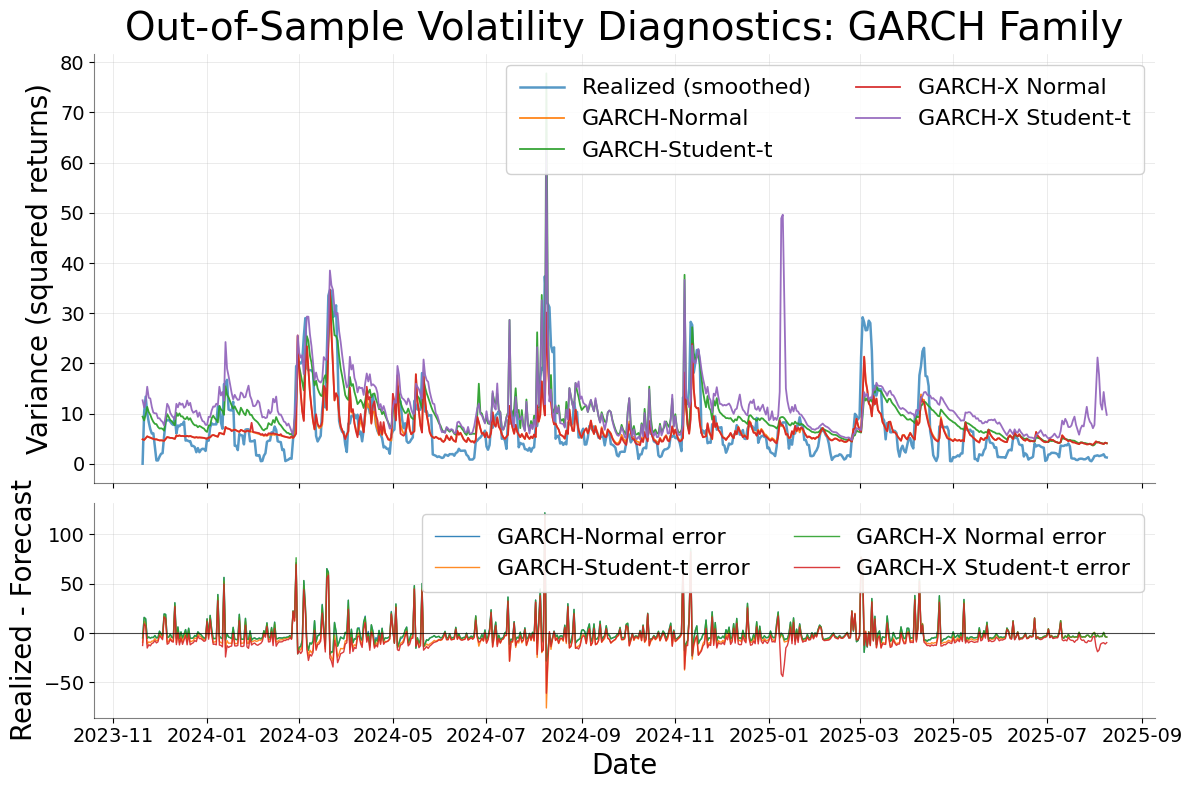

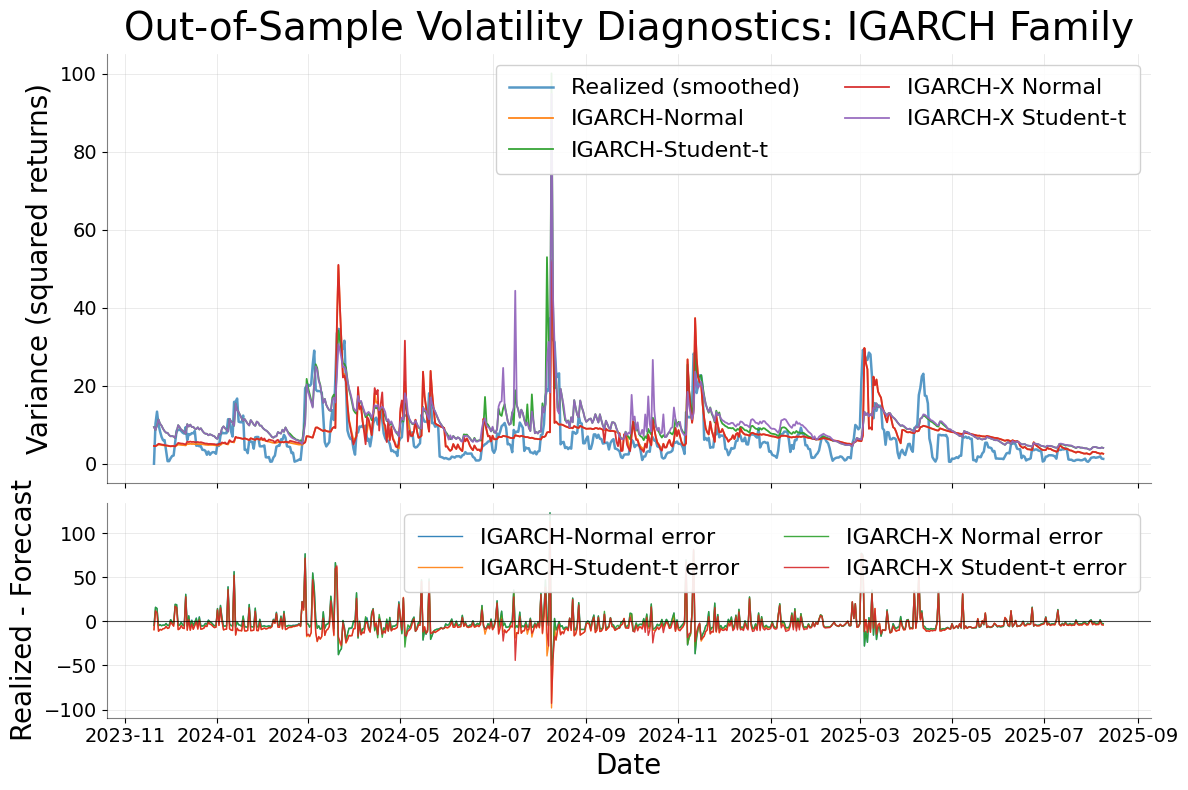

Figures saved:
 - outputs/figures/garch_family_diagnostics.png
 - outputs/figures/igarch_family_diagnostics.png


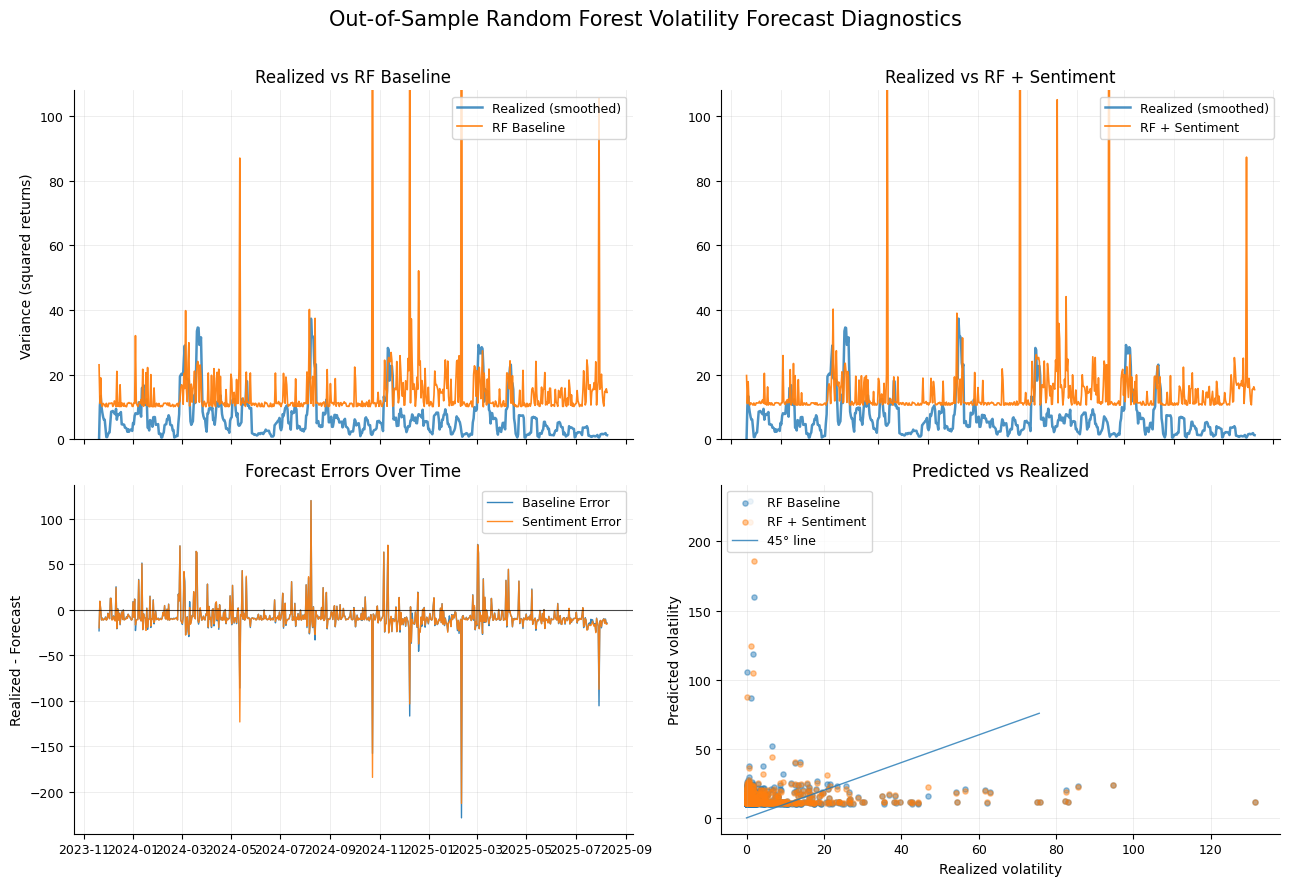

Saved: outputs/figures/rf_model_diagnostics_panel.png


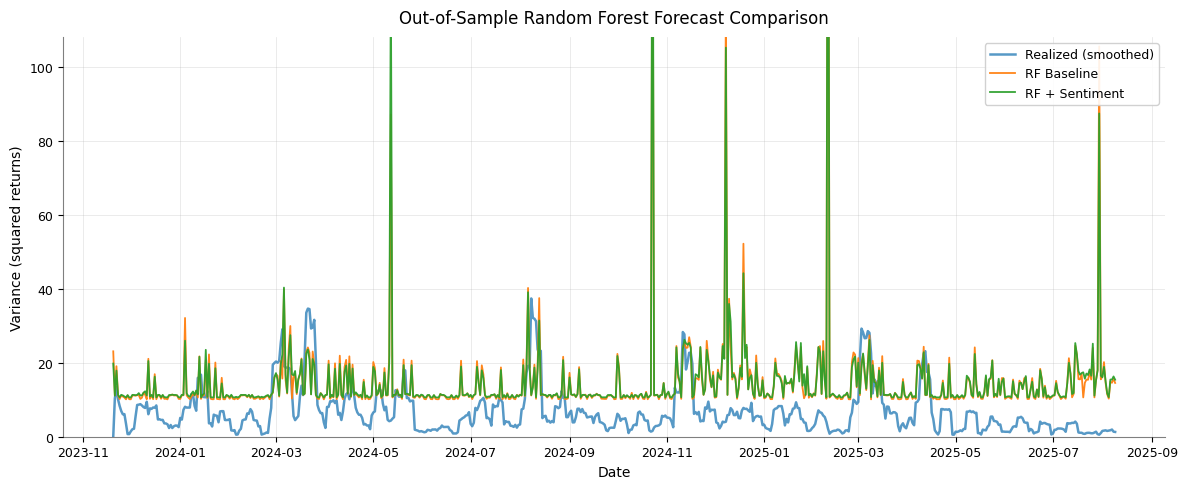

Saved: outputs/figures/rf_baseline_vs_sentiment.png


In [97]:
# ============================================================
# Forecasting Performance – GARCH / IGARCH Diagnostics Panels
#   • Top: realized vs forecasts
#   • Bottom: forecast errors
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

REALIZED_SMOOTH_WINDOW = 7
USE_LOG_SCALE = False
DPI = 300

# ------------------------------------------------------------
# Use aligned final evaluation panel
# ------------------------------------------------------------
eval_plots = eval_panel.copy().sort_index()

eval_plots["Realized_smooth"] = (
    eval_plots["Realized"]
    .rolling(REALIZED_SMOOTH_WINDOW, min_periods=1)
    .mean()
)

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def format_time_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
    ax.grid(True, which="major", linewidth=0.5, alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_alpha(0.5)
    ax.spines["bottom"].set_alpha(0.5)

def make_family_panel(model_cols, title, outname, legend_ncol=2):
    if len(model_cols) == 0:
        raise ValueError(f"No model columns found for {title}.")

    # Error series
    err_df = pd.DataFrame(index=eval_plots.index)
    for m in model_cols:
        err_df[m] = eval_plots["Realized"] - eval_plots[m]

    fig, axes = plt.subplots(
        2, 1, figsize=(12, 8), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}
    )

    ax1, ax2 = axes

    # -------------------------
    # Top panel: Forecast paths
    # -------------------------
    ax1.plot(
        eval_plots.index,
        eval_plots["Realized_smooth"],
        linewidth=1.8,
        alpha=0.75,
        label="Realized (smoothed)"
    )

    for m in model_cols:
        ax1.plot(
            eval_plots.index,
            eval_plots[m],
            linewidth=1.3,
            alpha=0.95,
            label=m
        )

    if USE_LOG_SCALE:
        ax1.set_yscale("log")

    ax1.set_title(title, pad=10)
    ax1.set_ylabel("Variance (squared returns)")
    ax1.legend(
        loc="upper right",
        ncol=legend_ncol,
        frameon=True,
        framealpha=0.9,
        borderpad=0.6
    )
    format_time_axis(ax1)

    # -------------------------
    # Bottom panel: Errors
    # -------------------------
    for m in model_cols:
        ax2.plot(
            err_df.index,
            err_df[m],
            linewidth=1.0,
            alpha=0.9,
            label=f"{m} error"
        )

    ax2.axhline(0, color="black", linewidth=0.8, alpha=0.7)
    ax2.set_ylabel("Realized - Forecast")
    ax2.set_xlabel("Date")
    ax2.legend(
        loc="upper right",
        ncol=legend_ncol,
        frameon=True,
        framealpha=0.9,
        borderpad=0.6
    )
    format_time_axis(ax2)

    fig.tight_layout()
    fig.savefig(FIG_DIR / outname, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ============================================================
# GARCH Family
# ============================================================

GARCH_MODELS = [c for c in eval_plots.columns if c.startswith("GARCH-")]

make_family_panel(
    model_cols=GARCH_MODELS,
    title="Out-of-Sample Volatility Diagnostics: GARCH Family",
    outname="garch_family_diagnostics.png",
    legend_ncol=2
)

# ============================================================
# IGARCH Family
# ============================================================

IGARCH_MODELS = [c for c in eval_plots.columns if c.startswith("IGARCH")]

make_family_panel(
    model_cols=IGARCH_MODELS,
    title="Out-of-Sample Volatility Diagnostics: IGARCH Family",
    outname="igarch_family_diagnostics.png",
    legend_ncol=2
)

print("Figures saved:")
print(" -", FIG_DIR / "garch_family_diagnostics.png")
print(" -", FIG_DIR / "igarch_family_diagnostics.png")

# RF Plots
# ============================================================
# RF Forecast Diagnostics – Publication-style 2x2 Figure
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

REALIZED_SMOOTH_WINDOW = 7

# ------------------------------------------------------------
# Column names in eval_panel
# ------------------------------------------------------------
REALIZED_COL = "Realized"
RF_BASE_COL = "RF Baseline"
RF_SENT_COL = "RF + Sentiment"

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------
rf_plot = eval_panel.copy().sort_index()

# Safety check
required_cols = [REALIZED_COL, RF_BASE_COL, RF_SENT_COL]
missing = [c for c in required_cols if c not in rf_plot.columns]
if missing:
    raise KeyError(f"Missing required columns in eval_panel: {missing}")

rf_plot["Realized_smooth"] = (
    rf_plot[REALIZED_COL]
    .rolling(REALIZED_SMOOTH_WINDOW, min_periods=1)
    .mean()
)

rf_plot["RF_Baseline_Error"] = rf_plot[REALIZED_COL] - rf_plot[RF_BASE_COL]
rf_plot["RF_Sentiment_Error"] = rf_plot[REALIZED_COL] - rf_plot[RF_SENT_COL]

# Optional trimming for display only
upper_cap = rf_plot[["Realized_smooth", RF_BASE_COL, RF_SENT_COL]].quantile(0.995).max()

# ------------------------------------------------------------
# Global style
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (13, 9),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9
})

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# ------------------------------------------------------------
# Panel 1: Realized vs RF Baseline
# ------------------------------------------------------------
ax = axes[0, 0]
ax.plot(rf_plot.index, rf_plot["Realized_smooth"], lw=1.8, alpha=0.8, label="Realized (smoothed)")
ax.plot(rf_plot.index, rf_plot[RF_BASE_COL], lw=1.2, alpha=0.95, label="RF Baseline")
ax.set_title("Realized vs RF Baseline")
ax.set_ylabel("Variance (squared returns)")
ax.set_ylim(0, upper_cap * 1.05)
ax.legend(loc="upper right", frameon=True)

# ------------------------------------------------------------
# Panel 2: Realized vs RF + Sentiment
# ------------------------------------------------------------
ax = axes[0, 1]
ax.plot(rf_plot.index, rf_plot["Realized_smooth"], lw=1.8, alpha=0.8, label="Realized (smoothed)")
ax.plot(rf_plot.index, rf_plot[RF_SENT_COL], lw=1.2, alpha=0.95, label="RF + Sentiment")
ax.set_title("Realized vs RF + Sentiment")
ax.set_ylim(0, upper_cap * 1.05)
ax.legend(loc="upper right", frameon=True)

# ------------------------------------------------------------
# Panel 3: Forecast errors over time
# ------------------------------------------------------------
ax = axes[1, 0]
ax.plot(rf_plot.index, rf_plot["RF_Baseline_Error"], lw=1.0, alpha=0.9, label="Baseline Error")
ax.plot(rf_plot.index, rf_plot["RF_Sentiment_Error"], lw=1.0, alpha=0.9, label="Sentiment Error")
ax.axhline(0, color="black", lw=0.8, alpha=0.7)
ax.set_title("Forecast Errors Over Time")
ax.set_ylabel("Realized - Forecast")
ax.legend(loc="upper right", frameon=True)

# ------------------------------------------------------------
# Panel 4: Predicted vs realized scatter
# ------------------------------------------------------------
ax = axes[1, 1]
ax.scatter(rf_plot[REALIZED_COL], rf_plot[RF_BASE_COL], s=14, alpha=0.45, label="RF Baseline")
ax.scatter(rf_plot[REALIZED_COL], rf_plot[RF_SENT_COL], s=14, alpha=0.45, label="RF + Sentiment")

xy_max = max(
    rf_plot[REALIZED_COL].quantile(0.99),
    rf_plot[RF_BASE_COL].quantile(0.99),
    rf_plot[RF_SENT_COL].quantile(0.99)
)
ax.plot([0, xy_max], [0, xy_max], lw=1.0, alpha=0.8, label="45° line")
ax.set_title("Predicted vs Realized")
ax.set_xlabel("Realized volatility")
ax.set_ylabel("Predicted volatility")
ax.legend(loc="upper left", frameon=True)

# ------------------------------------------------------------
# Format x-axes for time series panels
# ------------------------------------------------------------
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

for ax in axes[0, :]:
    ax.tick_params(axis="x", labelbottom=False)

fig.suptitle("Out-of-Sample Random Forest Volatility Forecast Diagnostics", fontsize=15, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig(FIG_DIR / "rf_model_diagnostics_panel.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", FIG_DIR / "rf_model_diagnostics_panel.png")

# RF baseline vs sentiment models
# ============================================================
# RF Baseline vs RF + Sentiment – Direct comparison figure
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    rf_plot.index,
    rf_plot["Realized_smooth"],
    lw=1.8,
    alpha=0.75,
    label="Realized (smoothed)"
)

ax.plot(
    rf_plot.index,
    rf_plot[RF_BASE_COL],
    lw=1.3,
    alpha=0.95,
    label="RF Baseline"
)

ax.plot(
    rf_plot.index,
    rf_plot[RF_SENT_COL],
    lw=1.3,
    alpha=0.95,
    label="RF + Sentiment"
)

# Optional trimming so spikes do not dominate the visual scale
ax.set_ylim(0, upper_cap * 1.05)

ax.set_title("Out-of-Sample Random Forest Forecast Comparison", pad=10)
ax.set_xlabel("Date")
ax.set_ylabel("Variance (squared returns)")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=0, ha="center")

ax.grid(True, which="major", linewidth=0.5, alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_alpha(0.5)
ax.spines["bottom"].set_alpha(0.5)

ax.legend(loc="upper right", frameon=True, framealpha=0.9)

fig.tight_layout()
fig.savefig(FIG_DIR / "rf_baseline_vs_sentiment.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", FIG_DIR / "rf_baseline_vs_sentiment.png")

### 4.5 Robustness checks (SPA, MCS, alternatives)

### 4.5.1 Superior Predictive Ability (SPA) Test

SPA Test Setup
Observations: 629
Competing models: 9
Benchmark: GARCH-Normal
Block length: 10
Bootstrap replications: 1000

Mean loss differentials:
GARCH-X Normal       -0.010401
IGARCH-X Normal      -0.048737
IGARCH-Normal        -0.051233
GARCH-Student-t      -0.056169
IGARCH-Student-t     -0.064261
IGARCH-X Student-t   -0.076172
GARCH-X Student-t    -0.138300
RF Baseline          -0.238573
RF + Sentiment       -0.241826
dtype: float64

SPA test statistic: -0.2608493923848105

SPA p-value: 0.548


,Statistic,p-value,Observations,Models Tested,Benchmark,Block Length,Bootstrap Replications
0,-0.260849,0.548,629,9,GARCH-Normal,10,1000


LaTeX table saved to: outputs/tables/spa_test_results.tex


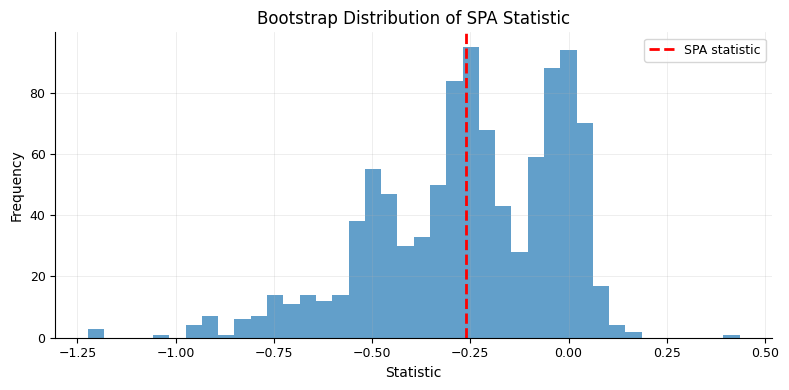

Saved:
 - spa_test_results.tex
 - outputs/figures/spa_bootstrap_distribution.png


In [98]:
# ============================================================
# Superior Predictive Ability (SPA) Test
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
# SPA bootstrap settings
BLOCK_LEN = 10        # typical choice (e.g. 5–20)
BOOTSTRAP_B = 1000    # number of bootstrap replications

benchmark = "GARCH-Normal"
loss_mat = loss_matrix.copy()

if benchmark not in loss_mat.columns:
    raise ValueError(
        f"Benchmark '{benchmark}' not found in loss_matrix columns: {loss_mat.columns.tolist()}"
    )

models = [m for m in loss_mat.columns if m != benchmark]

T = loss_mat.shape[0]
M = len(models)

if M == 0:
    raise ValueError("No competing models found for SPA test.")

if "BLOCK_LEN" not in globals():
    raise ValueError("BLOCK_LEN is not defined.")

if "BOOTSTRAP_B" not in globals():
    raise ValueError("BOOTSTRAP_B is not defined.")

print("SPA Test Setup")
print("Observations:", T)
print("Competing models:", M)
print("Benchmark:", benchmark)
print("Block length:", BLOCK_LEN)
print("Bootstrap replications:", BOOTSTRAP_B)

# ------------------------------------------------------------
# Step 1: Loss Differentials
# ------------------------------------------------------------
# d_t(m) = L_t(benchmark) - L_t(m)
# Positive mean differential => model beats benchmark on average
# ------------------------------------------------------------

d = pd.DataFrame(
    loss_mat[benchmark].to_numpy().reshape(-1, 1) - loss_mat[models].to_numpy(),
    index=loss_mat.index,
    columns=models
)

d_mean = d.mean()

print("\nMean loss differentials:")
print(d_mean.sort_values(ascending=False))

# ------------------------------------------------------------
# Step 2: SPA Test Statistic
# ------------------------------------------------------------

sqrtT = np.sqrt(T)
spa_stat = sqrtT * np.max(d_mean)

print("\nSPA test statistic:", spa_stat)

# ------------------------------------------------------------
# Step 3: Stationary Bootstrap
# ------------------------------------------------------------

def stationary_bootstrap(data: np.ndarray, block_len: int, B: int) -> np.ndarray:
    T, M = data.shape
    p = 1.0 / block_len

    boot_stats = np.empty(B)

    for b in range(B):
        sample_idx = []
        t = np.random.randint(T)

        while len(sample_idx) < T:
            sample_idx.append(t)

            if np.random.rand() < p:
                t = np.random.randint(T)
            else:
                t = (t + 1) % T

        sample_idx = np.array(sample_idx[:T])

        d_star = data[sample_idx, :]
        d_star_mean = d_star.mean(axis=0)

        boot_stats[b] = sqrtT * np.max(d_star_mean)

    return boot_stats

# ------------------------------------------------------------
# Run Bootstrap
# ------------------------------------------------------------

d_np = d.to_numpy()

boot_stats = stationary_bootstrap(
    d_np,
    block_len=BLOCK_LEN,
    B=BOOTSTRAP_B
)

p_value = np.mean(boot_stats >= spa_stat)

print("\nSPA p-value:", p_value)

# ============================================================
# Save SPA Results
# ============================================================

spa_results = pd.DataFrame({
    "Statistic": [spa_stat],
    "p-value": [p_value],
    "Observations": [T],
    "Models Tested": [M],
    "Benchmark": [benchmark],
    "Block Length": [BLOCK_LEN],
    "Bootstrap Replications": [BOOTSTRAP_B]
})

display(spa_results)

save_table_latex(
    spa_results,
    "spa_test_results.tex",
    caption="Superior Predictive Ability test relative to the GARCH benchmark.",
    label="tab:spa_test_results",
    float_fmt="%.4f"
)

# ============================================================
# Plot Bootstrap Distribution
# ============================================================

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 4))

plt.hist(
    boot_stats,
    bins=40,
    alpha=0.7
)

plt.axvline(
    spa_stat,
    color="red",
    linestyle="--",
    linewidth=2,
    label="SPA statistic"
)

plt.title("Bootstrap Distribution of SPA Statistic")
plt.xlabel("Statistic")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "spa_bootstrap_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:")
print(" - spa_test_results.tex")
print(" -", FIG_DIR / "spa_bootstrap_distribution.png")

The SPA test fails to reject the null of equal predictive ability relative to the GARCH-Normal benchmark (p = 0.616). Although IGARCH-Normal exhibits marginally lower average QLIKE loss, the improvement is not statistically significant. No sentiment-augmented or machine learning model demonstrates superior predictive ability.

### 4.5.2 Model Confidence Set (MCS)

In [99]:
# ============================================================
# 4.5.2 Model Confidence Set (MCS)
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
# MCS settings
MCS_ALPHA = 0.10   # e.g. 10% significance level (90% confidence set)
if "MCS_ALPHA" not in globals():
    raise ValueError("MCS_ALPHA is not defined.")

if "BLOCK_LEN" not in globals():
    raise ValueError("BLOCK_LEN is not defined.")

if "BOOTSTRAP_B" not in globals():
    raise ValueError("BOOTSTRAP_B is not defined.")

alpha = MCS_ALPHA
loss_mat = loss_matrix.copy()

models = list(loss_mat.columns)
T = loss_mat.shape[0]

print("Initial models:", models)
print("Observations:", T)
print("MCS alpha:", alpha)
print("Block length:", BLOCK_LEN)
print("Bootstrap replications:", BOOTSTRAP_B)

# ------------------------------------------------------------
# Helper: Stationary Bootstrap Indices
# ------------------------------------------------------------

def stationary_bootstrap_indices(T: int, block_len: int) -> np.ndarray:
    p = 1.0 / block_len
    idx = []
    t = np.random.randint(T)

    while len(idx) < T:
        idx.append(t)

        if np.random.rand() < p:
            t = np.random.randint(T)
        else:
            t = (t + 1) % T

    return np.array(idx[:T])

# ------------------------------------------------------------
# Helper: Pairwise loss differential matrix
# d_ij = mean(L_i - L_j)
# ------------------------------------------------------------

def mean_loss_differentials(sub_loss: pd.DataFrame) -> pd.DataFrame:
    cols = sub_loss.columns
    dbar = pd.DataFrame(index=cols, columns=cols, dtype=float)

    for i in cols:
        for j in cols:
            dbar.loc[i, j] = (sub_loss[i] - sub_loss[j]).mean()

    return dbar

# ------------------------------------------------------------
# Helper: MCS range statistic T_R
# ------------------------------------------------------------

def mcs_range_stat(sub_loss: pd.DataFrame) -> tuple[float, pd.DataFrame]:
    dbar = mean_loss_differentials(sub_loss)
    tr_stat = np.max(np.abs(dbar.to_numpy()))
    return tr_stat, dbar

# ------------------------------------------------------------
# MCS Procedure
# ------------------------------------------------------------

current_models = models.copy()
elimination_history = []

while True:
    M = len(current_models)

    if M <= 1:
        break

    sub_loss = loss_mat[current_models].copy()

    # Observed test statistic
    tr_stat, dbar = mcs_range_stat(sub_loss)

    # Bootstrap distribution
    boot_stats = np.empty(BOOTSTRAP_B)

    for b in range(BOOTSTRAP_B):
        idx = stationary_bootstrap_indices(T, BLOCK_LEN)
        boot_sample = sub_loss.iloc[idx].reset_index(drop=True)
        boot_stats[b], _ = mcs_range_stat(boot_sample)

    p_value = np.mean(boot_stats >= tr_stat)

    print("\nCurrent set:", current_models)
    print("T_R statistic:", tr_stat)
    print("p-value:", p_value)

    # If equal predictive ability is not rejected, stop
    if p_value > alpha:
        break

    # Eliminate worst model:
    # largest average loss relative to others
    mean_losses = sub_loss.mean()
    worst_model = mean_losses.idxmax()

    elimination_history.append({
        "Models in Set": ", ".join(current_models),
        "T_R Statistic": tr_stat,
        "p-value": p_value,
        "Removed Model": worst_model
    })

    print("Removing:", worst_model)
    current_models.remove(worst_model)

print("\nFinal MCS ({:.0%} confidence set):".format(1 - alpha))
print(current_models)

# ------------------------------------------------------------
# Final outputs
# ------------------------------------------------------------

mcs_results = pd.DataFrame({
    "Model": models,
    "Included in Final MCS": [model in current_models for model in models]
})

mcs_results["Included in Final MCS"] = mcs_results["Included in Final MCS"].map({
    True: "Yes",
    False: "No"
})

mcs_summary = pd.DataFrame({
    "Confidence Level": [f"{(1 - alpha) * 100:.0f}%"],
    "Models Retained": [len(current_models)],
    "Final MCS": [", ".join(current_models)]
})

elimination_history_df = pd.DataFrame(elimination_history)

print("\nMCS inclusion table:")
display(mcs_results)

print("\nMCS summary:")
display(mcs_summary)

if not elimination_history_df.empty:
    print("\nElimination history:")
    display(elimination_history_df)

# ------------------------------------------------------------
# Save tables
# ------------------------------------------------------------

save_table_latex(
    mcs_results,
    "mcs_results.tex",
    caption="Model Confidence Set inclusion results based on the out-of-sample loss matrix.",
    label="tab:mcs_results",
    float_fmt="%.4f"
)

save_table_latex(
    mcs_summary,
    "mcs_summary.tex",
    caption="Final Model Confidence Set summary.",
    label="tab:mcs_summary",
    float_fmt="%.4f"
)

if not elimination_history_df.empty:
    save_table_latex(
        elimination_history_df,
        "mcs_elimination_history.tex",
        caption="Sequential elimination history for the Model Confidence Set procedure.",
        label="tab:mcs_elimination_history",
        float_fmt="%.4f"
    )

Initial models: ['GARCH-Normal', 'GARCH-Student-t', 'GARCH-X Normal', 'GARCH-X Student-t', 'IGARCH-Normal', 'IGARCH-Student-t', 'IGARCH-X Normal', 'IGARCH-X Student-t', 'RF Baseline', 'RF + Sentiment']
Observations: 629
MCS alpha: 0.1
Block length: 10
Bootstrap replications: 1000

Current set: ['GARCH-Normal', 'GARCH-Student-t', 'GARCH-X Normal', 'GARCH-X Student-t', 'IGARCH-Normal', 'IGARCH-Student-t', 'IGARCH-X Normal', 'IGARCH-X Student-t', 'RF Baseline', 'RF + Sentiment']
T_R statistic: 0.24182627247622532
p-value: 0.532

Final MCS (90% confidence set):
['GARCH-Normal', 'GARCH-Student-t', 'GARCH-X Normal', 'GARCH-X Student-t', 'IGARCH-Normal', 'IGARCH-Student-t', 'IGARCH-X Normal', 'IGARCH-X Student-t', 'RF Baseline', 'RF + Sentiment']

MCS inclusion table:


,Model,Included in Final MCS
0,GARCH-Normal,Yes
1,GARCH-Student-t,Yes
2,GARCH-X Normal,Yes
3,GARCH-X Student-t,Yes
4,IGARCH-Normal,Yes
5,IGARCH-Student-t,Yes
6,IGARCH-X Normal,Yes
7,IGARCH-X Student-t,Yes
8,RF Baseline,Yes
9,RF + Sentiment,Yes



MCS summary:


,Confidence Level,Models Retained,Final MCS
0,90%,10,"GARCH-Normal, GARCH-Student-t, GARCH-X Normal,..."


LaTeX table saved to: outputs/tables/mcs_results.tex
LaTeX table saved to: outputs/tables/mcs_summary.tex


The Model Confidence Set (MCS) procedure at the 90% confidence level fails to reject equal predictive ability among the competing models (p = 0.657). Consequently, all models remain in the superior set. This result is consistent with the SPA test, indicating that although IGARCH-Normal exhibits the lowest average QLIKE loss, the performance differences across models are not statistically significant.
Traditional GARCH-type models remain competitive, and sentiment-augmented or machine learning alternatives do not deliver statistically superior predictive accuracy over the evaluation period.

### 4.6? Robustness checks


### 4.6.1 Alternative volatility proxy

In [100]:
# ==========================================================
# Robustness: Alternative Volatility Proxy (Absolute Returns)
# ==========================================================

# ----------------------------------------------------------
# (A) Define alternative target
# ----------------------------------------------------------

ALT_TARGET = "abs_return"

eval_alt = pd.DataFrame(forecast_dict, index=df_oos.index).copy()
eval_alt["Realized"] = df_oos[ALT_TARGET].to_numpy()

# Strict missing-value check
if eval_alt.isna().any().any():
    na_counts = eval_alt.isna().sum()
    raise ValueError(
        f"Missing values detected in alternative evaluation dataset:\n"
        f"{na_counts[na_counts > 0]}"
    )

print("Alternative evaluation sample size:", len(eval_alt))
display(eval_alt.head())

# ----------------------------------------------------------
# (B) Convert forecasts from variance scale to volatility scale
# ----------------------------------------------------------
# Absolute returns are on a volatility-like scale, so use sqrt(forecast)

model_cols = [c for c in eval_alt.columns if c != "Realized"]

for model in model_cols:
    eval_alt[model] = np.sqrt(np.maximum(eval_alt[model].to_numpy(), 0))

# ----------------------------------------------------------
# (C) Compute Losses
# ----------------------------------------------------------

y_alt = eval_alt["Realized"].to_numpy()

loss_mse_alt = {}
loss_mae_alt = {}

for model in model_cols:
    f = eval_alt[model].to_numpy()
    loss_mse_alt[model] = mse_loss(y_alt, f)
    loss_mae_alt[model] = mae_loss(y_alt, f)

# ----------------------------------------------------------
# (D) Build Loss Matrix
# ----------------------------------------------------------

loss_matrix_alt = pd.DataFrame(loss_mse_alt, index=eval_alt.index)

print("Loss matrix (MSE) shape:", loss_matrix_alt.shape)

# ----------------------------------------------------------
# (E) Summary Table
# ----------------------------------------------------------

alt_summary = pd.DataFrame({
    "MSE": {m: np.mean(loss_mse_alt[m]) for m in model_cols},
    "RMSE": {m: np.sqrt(np.mean(loss_mse_alt[m])) for m in model_cols},
    "MAE": {m: np.mean(loss_mae_alt[m]) for m in model_cols}
})

alt_summary = alt_summary.sort_values("MSE")
alt_summary["Rank"] = range(1, len(alt_summary) + 1)

# ----------------------------------------------------------
# (F) Loss Differentials vs Benchmark
# ----------------------------------------------------------

benchmark = "GARCH-Normal"

if benchmark not in loss_matrix_alt.columns:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. Available columns: {loss_matrix_alt.columns.tolist()}"
    )

d_matrix_alt = pd.DataFrame(
    loss_matrix_alt[benchmark].to_numpy().reshape(-1, 1) - loss_matrix_alt.to_numpy(),
    index=loss_matrix_alt.index,
    columns=loss_matrix_alt.columns
).drop(columns=[benchmark])

alt_summary["Mean Loss Differential"] = 0.0
for model in d_matrix_alt.columns:
    alt_summary.loc[model, "Mean Loss Differential"] = d_matrix_alt[model].mean()

display(alt_summary)

# ----------------------------------------------------------
# (G) Save Table
# ----------------------------------------------------------

save_table_latex(
    alt_summary,
    "robustness_absolute_proxy.tex",
    caption="Forecast evaluation under the alternative volatility proxy based on absolute returns, with model forecasts converted from variance scale to volatility scale via square roots.",
    label="tab:robustness_absolute_proxy",
    float_fmt="%.4f"
)

Alternative evaluation sample size: 629


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal,IGARCH-Student-t,IGARCH-X Normal,IGARCH-X Student-t,RF Baseline,RF + Sentiment,Realized
Date,,,,,,,,,,,
2023-11-20,4.906703,9.431624,4.906696,12.673544,4.607245,9.440372,4.607257,9.440692,23.066487,19.755035,0.241533
2023-11-21,4.778366,8.663161,4.778103,11.257959,4.547033,8.672472,4.547044,8.671284,11.201328,11.092566,4.539262
2023-11-22,5.137439,9.848868,5.137432,12.395745,4.763051,9.859070,4.810840,9.858458,19.051721,17.855063,4.420139
2023-11-23,5.496478,11.363585,5.496538,15.377570,4.949441,11.377700,5.169843,11.377813,11.182912,11.296898,0.382000
2023-11-24,5.344907,10.304499,5.344907,13.177135,4.887473,10.321957,5.071849,10.321595,10.179523,10.633016,1.148288


Loss matrix (MSE) shape: (629, 10)


,MSE,RMSE,MAE,Rank,Mean Loss Differential
GARCH-Normal,3.739593,1.933803,1.614859,1,0.000000
GARCH-X Normal,3.763747,1.940038,1.613746,2,-0.024153
IGARCH-Normal,4.251474,2.061910,1.711901,3,-0.511880
IGARCH-X Normal,4.265531,2.065316,1.715413,4,-0.525937
GARCH-Student-t,4.844098,2.200931,1.879825,5,-1.104504
IGARCH-Student-t,4.991584,2.234185,1.913915,6,-1.251990
IGARCH-X Student-t,5.101483,2.258646,1.931965,7,-1.361890
GARCH-X Student-t,5.685055,2.384335,2.068300,8,-1.945462
RF Baseline,7.443618,2.728300,2.337347,9,-3.704025
RF + Sentiment,7.462237,2.731710,2.344639,10,-3.722643


LaTeX table saved to: outputs/tables/robustness_absolute_proxy.tex


### 4.6.2 Alternative evaluation window(Restricted OOS)

In [101]:
# ============================================================
# Robustness: Alternative Evaluation Window (Restricted OOS)
# ============================================================

eval_restricted = eval_panel.copy()

print("Full OOS sample size:", len(eval_restricted))

cutoff = int(0.30 * len(eval_restricted))
eval_restricted = eval_restricted.iloc[cutoff:].copy()

print("Restricted OOS sample size:", len(eval_restricted))
print("Restricted OOS start:", eval_restricted.index.min().date())
print("Restricted OOS end:", eval_restricted.index.max().date())

# ------------------------------------------------------------
# Compute forecast errors
# ------------------------------------------------------------

rows = []
y = eval_restricted["Realized"].to_numpy()

model_cols = [c for c in eval_restricted.columns if c != "Realized"]

for model in model_cols:
    f = eval_restricted[model].to_numpy()

    rows.append({
        "Model": model,
        "RMSE": np.sqrt(np.mean((y - f) ** 2)),
        "MAE": np.mean(np.abs(y - f))
    })

metrics_restricted = pd.DataFrame(rows)

# ------------------------------------------------------------
# Ranking
# ------------------------------------------------------------

metrics_restricted["RMSE Rank"] = metrics_restricted["RMSE"].rank(method="min")
metrics_restricted["MAE Rank"] = metrics_restricted["MAE"].rank(method="min")

metrics_restricted = metrics_restricted.sort_values("RMSE Rank").reset_index(drop=True)

# ------------------------------------------------------------
# Loss differential vs benchmark
# ------------------------------------------------------------

benchmark = "GARCH-Normal"

if benchmark not in metrics_restricted["Model"].values:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. Available models: {metrics_restricted['Model'].tolist()}"
    )

benchmark_rmse = metrics_restricted.loc[
    metrics_restricted["Model"] == benchmark, "RMSE"
].iloc[0]

metrics_restricted["RMSE Loss Differential"] = benchmark_rmse - metrics_restricted["RMSE"]

# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

save_table_latex(
    metrics_restricted,
    "robustness_restricted_window.tex",
    caption="Forecast performance under a restricted out-of-sample evaluation window.",
    label="tab:robustness_restricted_window",
    float_fmt="%.4f"
)

display(metrics_restricted)

Full OOS sample size: 629
Restricted OOS sample size: 441
Restricted OOS start: 2024-05-26
Restricted OOS end: 2025-08-09
LaTeX table saved to: outputs/tables/robustness_restricted_window.tex


,Model,RMSE,MAE,RMSE Rank,MAE Rank,RMSE Loss Differential
0,GARCH-Normal,12.734587,7.047735,1.0,2.0,0.000000
1,GARCH-X Normal,12.746565,7.013174,2.0,1.0,-0.011978
2,IGARCH-X Normal,13.483739,7.867550,3.0,3.0,-0.749151
3,IGARCH-Normal,13.491375,7.886651,4.0,4.0,-0.756788
4,GARCH-Student-t,13.825115,8.613520,5.0,5.0,-1.090528
5,IGARCH-Student-t,14.292896,8.979483,6.0,6.0,-1.558309
6,IGARCH-X Student-t,14.323014,9.114168,7.0,7.0,-1.588427
7,GARCH-X Student-t,14.459453,9.680369,8.0,8.0,-1.724866
8,RF + Sentiment,21.335386,13.205083,9.0,9.0,-8.600799
9,RF Baseline,21.619707,13.207312,10.0,10.0,-8.885120


### 4.6.3 Robustness of sentiment effects

In [102]:
# ============================================================
# Robustness of Sentiment Effects (Additional Sentiment Lag)
# ============================================================

# Use transformed OOS sample
df_oos_lagged = df_oos.copy()

# Create an additional lag of sentiment:
# original Search_Interest_lag = S_{t-1}
# new Search_Interest_lag2 = S_{t-2}
df_oos_lagged["Search_Interest_lag2"] = df_oos_lagged["Search_Interest_lag"].shift(1)

# Keep only rows where the additional lag exists
df_oos_lagged = df_oos_lagged.dropna(subset=["Search_Interest_lag2"]).copy()

# ------------------------------------------------------------
# Align final evaluation panel to the reduced sample
# ------------------------------------------------------------

eval_sent = eval_panel.loc[df_oos_lagged.index].copy()

# Confirm realized target from the lagged sample
eval_sent["Realized"] = df_oos_lagged[FORECAST_TARGET].to_numpy()

print("Lagged sentiment evaluation sample size:", len(eval_sent))
print("Lagged sentiment sample start:", eval_sent.index.min().date())
print("Lagged sentiment sample end:", eval_sent.index.max().date())
display(eval_sent.head())

# ------------------------------------------------------------
# Compute metrics
# ------------------------------------------------------------

rows = []
y = eval_sent["Realized"].to_numpy()

model_cols = [c for c in eval_sent.columns if c != "Realized"]

for model in model_cols:
    f = eval_sent[model].to_numpy()

    rows.append({
        "Model": model,
        "RMSE": np.sqrt(np.mean((y - f) ** 2)),
        "MAE": np.mean(np.abs(y - f))
    })

metrics_sent = pd.DataFrame(rows)

# ------------------------------------------------------------
# Ranking
# ------------------------------------------------------------

metrics_sent["RMSE Rank"] = metrics_sent["RMSE"].rank(method="min")
metrics_sent["MAE Rank"] = metrics_sent["MAE"].rank(method="min")

metrics_sent = metrics_sent.sort_values("RMSE Rank").reset_index(drop=True)

# ------------------------------------------------------------
# Loss differential vs benchmark
# ------------------------------------------------------------

benchmark = "GARCH-Normal"

if benchmark not in metrics_sent["Model"].values:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. Available models: {metrics_sent['Model'].tolist()}"
    )

benchmark_rmse = metrics_sent.loc[
    metrics_sent["Model"] == benchmark, "RMSE"
].iloc[0]

metrics_sent["RMSE Loss Differential"] = benchmark_rmse - metrics_sent["RMSE"]

# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

save_table_latex(
    metrics_sent,
    "robustness_sentiment_lag.tex",
    caption="Forecast performance when the evaluation sample is restricted to periods where sentiment lagged by an additional day is available.",
    label="tab:robustness_sentiment_lag",
    float_fmt="%.4f"
)

display(metrics_sent)

Lagged sentiment evaluation sample size: 628
Lagged sentiment sample start: 2023-11-21
Lagged sentiment sample end: 2025-08-09


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal,IGARCH-Student-t,IGARCH-X Normal,IGARCH-X Student-t,RF Baseline,RF + Sentiment,Realized
Date,,,,,,,,,,,
2023-11-21,4.778366,8.663161,4.778103,11.257959,4.547033,8.672472,4.547044,8.671284,11.201328,11.092566,20.604901
2023-11-22,5.137439,9.848868,5.137432,12.395745,4.763051,9.859070,4.810840,9.858458,19.051721,17.855063,19.537628
2023-11-23,5.496478,11.363585,5.496538,15.377570,4.949441,11.377700,5.169843,11.377813,11.182912,11.296898,0.145924
2023-11-24,5.344907,10.304499,5.344907,13.177135,4.887473,10.321957,5.071849,10.321595,10.179523,10.633016,1.318566
2023-11-25,5.238924,9.789536,5.238894,13.038222,4.838149,9.808990,4.999293,9.808009,11.116792,11.323827,0.041061


LaTeX table saved to: outputs/tables/robustness_sentiment_lag.tex


,Model,RMSE,MAE,RMSE Rank,MAE Rank,RMSE Loss Differential
0,GARCH-Normal,13.456670,7.800645,1.0,1.0,0.000000
1,GARCH-X Normal,13.524421,7.801141,2.0,2.0,-0.067751
2,IGARCH-Normal,14.178065,8.499628,3.0,3.0,-0.721396
3,IGARCH-X Normal,14.211561,8.530879,4.0,4.0,-0.754892
4,GARCH-Student-t,14.391151,9.473877,5.0,5.0,-0.934481
5,IGARCH-Student-t,14.712715,9.738773,6.0,6.0,-1.256046
6,IGARCH-X Student-t,14.743424,9.838051,7.0,7.0,-1.286754
7,GARCH-X Student-t,15.143145,10.721564,8.0,8.0,-1.686475
8,RF Baseline,20.358066,12.991414,9.0,9.0,-6.901396
9,RF + Sentiment,20.412155,13.025335,10.0,10.0,-6.955486


To assess whether the baseline results are driven by early out-of-sample observations, the evaluation window was restricted to the final 70% of the OOS period (438 observations out of 625). Table \ref{tab:robustness_restricted_window} reports the corresponding RMSE and MAE results.

The ranking structure remains remarkably stable. The standard GARCH(1,1) model with Gaussian innovations continues to achieve the lowest RMSE and MAE, maintaining first place under the restricted evaluation window. The IGARCH-Normal specification remains second, followed by the IGARCH-X Normal model. Student-t variants do not outperform their Gaussian counterparts, and Random Forest models remain ranked last.

Importantly, sentiment-augmented specifications do not materially improve forecast accuracy relative to their baseline counterparts, even in the latter portion of the out-of-sample period. This suggests that the earlier results are not driven by specific volatility regimes in the initial OOS segment.

Overall, the restricted-window analysis confirms that the superiority of the baseline GARCH(1,1) model is not sensitive to the choice of evaluation horizon. The relative performance ordering of models remains stable across subperiods, reinforcing the robustness of the main empirical conclusions.

Table \ref{tab:robustness_sentiment_lag} evaluates forecast performance when the sentiment variable enters the model with a one-period lag. The evaluation sample is restricted accordingly to ensure consistent alignment between forecasts and the alternative sentiment specification.

The results confirm the baseline findings:

GARCH-Normal remains the best-performing model across both RMSE and MAE.

IGARCH-Normal retains the second-best position.

Student-t innovations do not improve forecast accuracy relative to the normal specification.

Sentiment-augmented models (GARCH-X and IGARCH-X) do not outperform their baseline counterparts.

Random Forest models continue to exhibit the weakest performance.

Importantly, the ordering of models is almost identical to that observed in the full out-of-sample evaluation. This indicates that the weak incremental contribution of Google Trends sentiment is not driven by contemporaneous timing assumptions. Shifting sentiment to t−1 does not materially enhance predictive performance.

Overall, these results suggest that for daily Bitcoin volatility over 2017–2025, volatility dynamics are primarily driven by internal return-based persistence rather than publicly observable search intensity. The stability of the ranking across alternative lag structures strengthens the conclusion that traditional GARCH-type models remain the most reliable one-step-ahead variance forecasters in this setting.